# **Домашняя работа №5**
## **Машина опорных векторов (SVM)**

**Выполнил:** Чубаев Кирилл Евгеньевич  
**Группа:** НПМбд-01-24  
**Преподаватель:** Карандашев Я. М.

## Цель работы

Целью данной работы является познакомиться с линейным и квадратичным программированием, реализовать линейную и ядровую машины опорных векторов, а также исследовать влияние их параметров и применить модели к реальным данным.

### Отчёт

Работа была оформлена в Google Colab.

При выполнении работы в целях дополнительных объяснений теоретического материала я использовал нейросеть ChatGPT.


## Подготовка библиотек

In [ ]:
import importlib.util
import subprocess
import sys

packages = {"numpy": "numpy", "matplotlib": "matplotlib",
            "pandas": "pandas", "cvxopt": "cvxopt", "sklearn": "scikit-learn", "threadpoolctl": "threadpoolctl"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxopt
import sklearn
from cvxopt import matrix, solvers

plt.rcParams.update({"font.size": 10.5, "axes.spines.top": False,
                     "axes.spines.right": False})
print(f"Библиотеки готовы. CVXOPT {cvxopt.__version__}, scikit-learn {sklearn.__version__}.")
from itertools import combinations
from threadpoolctl import threadpool_limits
_blas_limit = threadpool_limits(limits=1)
np.set_printoptions(precision=6,suppress=True)
plt.rcParams["lines.linewidth"]=2.2
solvers.options.update({"show_progress":False,"abstol":1e-10,
                       "reltol":1e-10,"feastol":1e-9,"maxiters":100})

Библиотеки готовы. CVXOPT 1.3.2, scikit-learn 1.6.1.


# Часть 1. Линейное и квадратичное программирование
## Теоретическое введение

**Линейное программирование (LP)** — оптимизация линейной функции при линейных ограничениях:
$$\min_x c^\top x,\qquad Gx\leq h,\quad Ax=b.$$
Здесь $x$ — искомый вектор переменных, $c$ — коэффициенты цели, каждая строка $G$ задаёт одно неравенство, $h$ — правые части этих неравенств. Матрица $A$ и вектор $b$ задают равенства, которые в наших задачах отсутствуют. Максимизацию переводим в минимизацию, меняя знак целевой функции.

**Квадратичное программирование (QP)** использует цель
$$\min_x \frac12 x^\top Px+q^\top x,\qquad Gx\leq h.$$
Симметричная матрица $P$ задаёт квадратичную часть, $q$ — линейную. Градиент равен $Px+q$, гессиан равен $P$. При $P\succ0$ цель строго выпукла, и минимум на непустом замкнутом выпуклом допустимом множестве единственен.

**Допустимая область** состоит из точек, которые выполняют все ограничения. **Активное ограничение** выполняется в решении как равенство. Его запас $h_i-g_i^\top x_\star$ равен нулю. При численных расчётах допускаем небольшую погрешность.

Для ограниченного многоугольника оптимум линейной функции достигается хотя бы в одной вершине. Если целевая функция параллельна оптимальному ребру, оптимально всё ребро. Утверждение из введения «внутренний оптимум невозможен» относится к непостоянной линейной цели на области с непустой внутренностью. У постоянной цели оптимальны все допустимые точки. Квадратичная цель может иметь внутренний минимум.


# Задание 1
## Часть A.
### 1.1.1 План производства мебели

Пусть $x_1$ — количество столов, $x_2$ — количество стульев. Прибыль в тысячах рублей равна $R(x)=3x_1+2x_2$. Задача:
$$\max_x (3x_1+2x_2),\qquad
2x_1+x_2\leq6,\quad x_1+x_2\leq4,\quad x_1,x_2\geq0.$$
Первое неравенство ограничивает время сборки, второе — время отделки. Рассматриваем непрерывную LP-модель. В исходной задаче найденный оптимальный план окажется целочисленным.

Для минимизации используем
$$c=\begin{pmatrix}-3\\-2\end{pmatrix},\quad
G=\begin{pmatrix}2&1\\1&1\\-1&0\\0&-1\end{pmatrix},\quad
h=\begin{pmatrix}6\\4\\0\\0\end{pmatrix}.$$

Матрицы создаём из массивов NumPy с типом double. Полученное значение цели солвера равно минус прибыли.

In [ ]:
profit = np.array([3., 2.])
G_lp = np.array([[2., 1.], [1., 1.], [-1., 0.], [0., -1.]])
h_lp = np.array([6., 4., 0., 0.])
lp = solvers.lp(matrix(-profit), matrix(G_lp), matrix(h_lp))
assert lp["status"] == "optimal"
x_lp = np.array(lp["x"]).ravel()
print("Статус:", lp["status"])
print("Оптимальный план:", x_lp)
print("Прибыль, тыс. руб.:", profit @ x_lp)
assert np.allclose(x_lp, [2, 2], atol=1e-6)

Статус: optimal
Оптимальный план: [2. 2.]
Прибыль, тыс. руб.: 9.999999999770534


### 1.1.2. Проверка перебором вершин

Каждую вершину получаем пересечением двух граничных прямых. Перебираем пары строк $G$, решаем соответствующую систему и оставляем точки, которые удовлетворяют всем ограничениям.

| Система двух уравнений | Вершина | Прибыль, тыс. руб. |
|---|---|---:|
| $x_1=0,\ x_2=0$ | $(0,0)$ | 0 |
| $2x_1+x_2=6,\ x_2=0$ | $(3,0)$ | 9 |
| $2x_1+x_2=6,\ x_1+x_2=4$ | $(2,2)$ | 10 |
| $x_1=0,\ x_1+x_2=4$ | $(0,4)$ | 8 |

Две другие пары дают $(0,6)$ и $(4,0)$. Эти точки нарушают хотя бы одно ограничение и не являются вершинами допустимой области.

In [ ]:
vertices = []
for pair in combinations(range(len(h_lp)), 2):
    indices = list(pair)
    M = G_lp[indices]
    if np.linalg.matrix_rank(M) == 2:
        point = np.linalg.solve(M, h_lp[indices])
        if np.all(G_lp @ point <= h_lp + 1e-9):
            vertices.append(point)
vertices = np.array(vertices)
center = vertices.mean(axis=0)
angles = np.arctan2(vertices[:, 1] - center[1], vertices[:, 0] - center[0])
vertices = vertices[np.argsort(angles)]
display(pd.DataFrame({"x₁": vertices[:, 0], "x₂": vertices[:, 1],
                      "Прибыль, тыс. руб.": vertices @ profit}))
assert len(vertices) == 4
assert np.isclose(np.max(vertices @ profit), profit @ x_lp)

,x₁,x₂,"Прибыль, тыс. руб."
0,-0.0,-0.0,0.0
1,3.0,-0.0,9.0
2,2.0,2.0,10.0
3,0.0,4.0,8.0


### 1.1.3. Другие коэффициенты прибыли и оптимальное ребро

Выберем прибыль $R_2(x)=2x_1+x_2$. Ограничение сборки даёт $R_2(x)\leq6$. На всём отрезке от $(2,2)$ до $(3,0)$ выполнено $2x_1+x_2=6$, поэтому каждая его точка оптимальна.

Солвер возвращает одну оптимальную точку. Внутренний метод CVXOPT может вернуть точку внутри этого отрезка. Конкретные координаты зависят от численных настроек, при этом прибыль должна быть близка к 6.

Возвращённая точка: [2.459112 1.081775]
Прибыль, тыс. руб.: 5.999999999980844


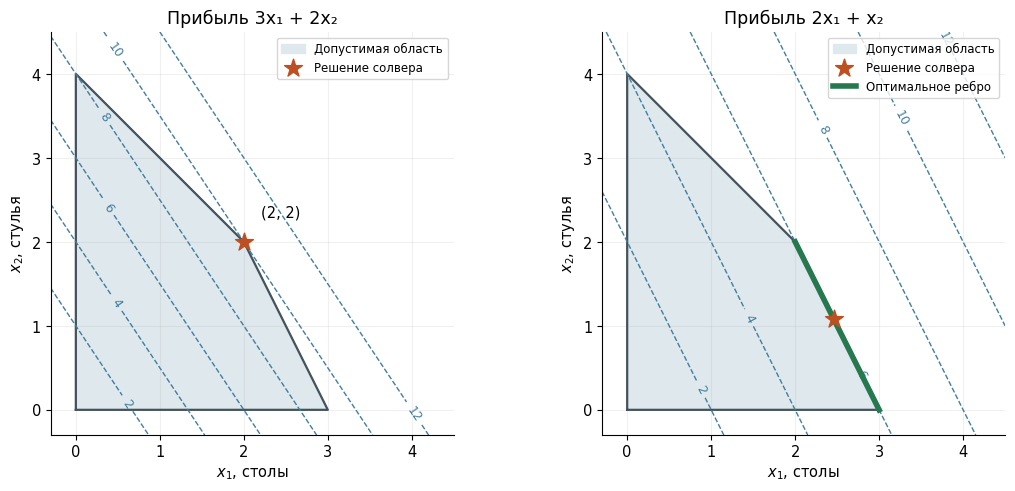

In [ ]:
edge_profit = np.array([2., 1.])
edge_lp = solvers.lp(matrix(-edge_profit), matrix(G_lp), matrix(h_lp))
assert edge_lp["status"] == "optimal"
x_edge = np.array(edge_lp["x"]).ravel()
print("Возвращённая точка:", x_edge)
print("Прибыль, тыс. руб.:", edge_profit @ x_edge)
assert np.all(G_lp @ x_edge <= h_lp + 1e-7)
assert np.isclose(edge_profit @ x_edge, 6, atol=1e-7)

grid = np.linspace(-0.3, 4.5, 300)
xx, yy = np.meshgrid(grid, grid)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), layout="constrained")
for ax, coeff, optimum, title in zip(
    axes, [profit, edge_profit], [x_lp, x_edge],
    ["Прибыль 3x₁ + 2x₂", "Прибыль 2x₁ + x₂"]
):
    ax.fill(vertices[:, 0], vertices[:, 1], color="#dfe8ec",
            label="Допустимая область")
    boundary = np.vstack([vertices, vertices[0]])
    ax.plot(boundary[:, 0], boundary[:, 1], color="#44525c", linewidth=1.6)
    cs = ax.contour(xx, yy, coeff[0]*xx + coeff[1]*yy,
                    levels=[2, 4, 6, 8, 10, 12], colors="#427e9e",
                    linestyles="--", linewidths=1)
    ax.clabel(cs, fontsize=9)
    ax.scatter(*optimum, marker="*", color="#be4f20", s=180,
               zorder=5, label="Решение солвера")
    ax.set(xlim=(-0.3, 4.5), ylim=(-0.3, 4.5), xlabel="$x_1$, столы",
           ylabel="$x_2$, стулья", title=title, aspect="equal")
    ax.grid(alpha=0.18)
axes[0].annotate("(2, 2)", (2, 2), xytext=(2.2, 2.3))
axes[1].plot([2, 3], [2, 0], color="#26794e", linewidth=4,
             label="Оптимальное ребро", zorder=4)
for ax in axes:
    ax.legend(loc="upper right", fontsize=8.5)
plt.show()

Серым показаны допустимые планы, пунктиром — линии одинаковой прибыли. На левом графике максимальная прибыль достигается в единственной вершине $(2,2)$. Используются все 6 часов сборки и все 4 часа отделки, прибыль равна 10 тыс. руб. На правом графике линия максимальной прибыли совпадает с выделенным ребром. У всех его точек прибыль равна 6 тыс. руб.

В непрерывной LP-модели допустимы дробные количества. Для целочисленного производства на этом ребре остаются два оптимальных плана — $(2,2)$ и $(3,0)$.

## Часть B.
### 1.2.1. Квадратичная задача

Минимизирую:
$$f(x)=x_1^2+4x_2^2-8x_1-16x_2,\qquad
x_1+x_2\leq5,\quad 0\leq x_1\leq3,\quad x_2\geq0.$$

### Минимум без ограничений и запись QP

Приравниваем градиент к нулю:
$$\nabla f(x)=\begin{pmatrix}2x_1-8\\8x_2-16\end{pmatrix}=0
\quad\Longrightarrow\quad x_{\mathrm{free}}=(4,2).$$
Гессиан $\operatorname{diag}(2,8)$ положительно определён, поэтому это единственный безусловный минимум. Он недопустим, поскольку $4>3$ и $4+2>5$.

В стандартной форме солвера
$$P=\begin{pmatrix}2&0\\0&8\end{pmatrix},\quad q=\begin{pmatrix}-8\\-16\end{pmatrix},
\quad G=\begin{pmatrix}1&1\\-1&0\\1&0\\0&-1\end{pmatrix},\quad
h=\begin{pmatrix}5\\0\\3\\0\end{pmatrix}.$$
Множитель $1/2$ в цели QP объясняет, почему диагональ $P$ равна $(2,8)$.

Представим цель как $f(x)=(x_1-4)^2+4(x_2-2)^2-32$. При $x_1\leq3$ первое слагаемое не меньше 1, а второе не меньше 0. Точка $(3,2)$ допустима и достигает этих нижних границ. Значит, точное решение — $(3,2)$, значение цели — $-31$.

Решение: [3.      1.99999]
Значение функции: -30.999999999586553


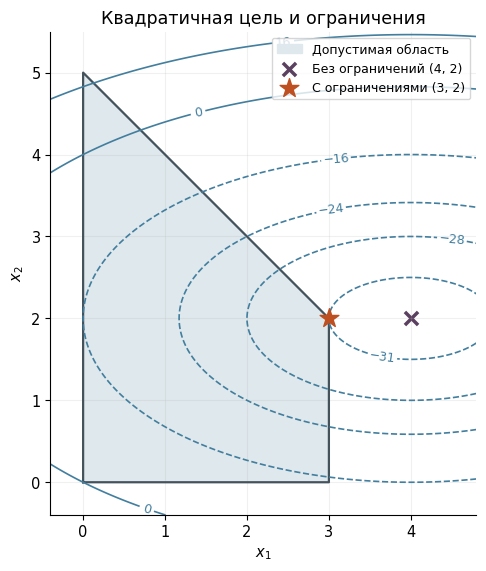

In [ ]:
P = np.diag([2., 8.])
q = np.array([-8., -16.])
G_qp = np.array([[1., 1.], [-1., 0.], [1., 0.], [0., -1.]])
h_qp = np.array([5., 0., 3., 0.])
names = ["x₁ + x₂ ≤ 5", "x₁ ≥ 0", "x₁ ≤ 3", "x₂ ≥ 0"]

def solve_qp(G, h):
    solution = solvers.qp(matrix(P), matrix(q), matrix(G), matrix(h))
    if solution["status"] != "optimal":
        raise RuntimeError(solution["status"])
    return np.array(solution["x"]).ravel()

def objective(x):
    return 0.5 * x @ P @ x + q @ x

x_qp = solve_qp(G_qp, h_qp)
print("Решение:", x_qp)
print("Значение функции:", objective(x_qp))
assert np.allclose(x_qp, [3, 2], atol=1e-4)

x1 = np.linspace(-0.4, 4.8, 350)
x2 = np.linspace(-0.4, 5.5, 350)
xx, yy = np.meshgrid(x1, x2)
values = (xx-4)**2 + 4*(yy-2)**2 - 32
polygon = np.array([[0, 0], [3, 0], [3, 2], [0, 5]])
fig, ax = plt.subplots(figsize=(6.7, 5.6), layout="constrained")
ax.fill(polygon[:, 0], polygon[:, 1], color="#dfe8ec", label="Допустимая область")
boundary = np.vstack([polygon, polygon[0]])
ax.plot(boundary[:, 0], boundary[:, 1], color="#44525c", linewidth=1.6)
cs = ax.contour(xx, yy, values, levels=[-31, -28, -24, -16, 0, 16],
                colors="#427e9e", linewidths=1.2)
ax.clabel(cs, fontsize=9)
ax.scatter(4, 2, marker="x", s=90, linewidths=2.5, color="#5b405f",
           label="Без ограничений (4, 2)")
ax.scatter(*x_qp, marker="*", s=200, color="#be4f20", zorder=5,
           label="С ограничениями (3, 2)")
ax.set(xlabel="$x_1$", ylabel="$x_2$", title="Квадратичная цель и ограничения",
       xlim=(-0.4, 4.8), ylim=(-0.4, 5.5), aspect="equal")
ax.grid(alpha=0.18)
ax.legend(loc="upper right", fontsize=9)
plt.show()

Линии уровня квадратичной функции — эллипсы с центром в $(4,2)$. Центр находится вне допустимого многоугольника. Самая низкая доступная линия уровня касается области в $(3,2)$, на пересечении границ $x_1=3$ и $x_1+x_2=5$.

### 1.2.2. Активные ограничения и эксперимент с удалением

В точном решении $(3,2)$ запасы ограничений равны $(0,3,0,2)$. Активны $x_1+x_2\leq5$ и $x_1\leq3$, неактивны $x_1\geq0$ и $x_2\geq0$.

Проверим удаление каждого ограничения по отдельности. Дополнительно оставим только $x_1\leq3$. Активность в таблице определяем с допуском $10^{-4}$, поскольку солвер возвращает приближённое решение.

In [ ]:
slacks = h_qp - G_qp @ x_qp
display(pd.DataFrame({
    "Ограничение": names, "Запас в точном решении": h_qp - G_qp @ np.array([3., 2.]),
    "Численный запас": slacks,
    "Активно": np.abs(slacks) < 1e-4,
}))

rows = [{"Удалено": "Ничего", "x₁": x_qp[0], "x₂": x_qp[1],
         "f(x)": objective(x_qp)}]
for i, name in enumerate(names):
    keep = np.arange(4) != i
    point = solve_qp(G_qp[keep], h_qp[keep])
    expected = [3.2, 1.8] if i == 2 else [3., 2.]
    assert np.allclose(point, expected, atol=1e-4)
    rows.append({"Удалено": name, "x₁": point[0], "x₂": point[1],
                 "f(x)": objective(point)})
point = solve_qp(G_qp[[2]], h_qp[[2]])
assert np.allclose(point, [3, 2], atol=1e-4)
rows.append({"Удалено": "Все, кроме x₁ ≤ 3", "x₁": point[0], "x₂": point[1],
             "f(x)": objective(point)})
display(pd.DataFrame(rows).round(6))

,Ограничение,Запас в точном решении,Численный запас,Активно
0,x₁ + x₂ ≤ 5,0.0,9.931470e-06,True
1,x₁ ≥ 0,3.0,3.000000e+00,False
2,x₁ ≤ 3,0.0,9.455547e-12,True
3,x₂ ≥ 0,2.0,1.999990e+00,False


,Удалено,x₁,x₂,f(x)
0,Ничего,3.0,1.999990,-31.0
1,x₁ + x₂ ≤ 5,3.0,2.000000,-31.0
2,x₁ ≥ 0,3.0,1.999985,-31.0
3,x₁ ≤ 3,3.2,1.800000,-31.2
4,x₂ ≥ 0,3.0,1.999983,-31.0
5,"Все, кроме x₁ ≤ 3",3.0,2.000000,-31.0


Проверка показала следующее: При удалении $x_1\geq0$ или $x_2\geq0$ оптимум сохраняется. Удаление активного ограничения $x_1+x_2\leq5$ тоже сохраняет $(3,2)$. Даже одного ограничения $x_1\leq3$ достаточно для этого минимума, что видно из записи цели через квадраты.

Если убрать $x_1\leq3$, решение переместится в $(3.2,1.8)$ и значение функции снизится до $-31.2$. Следовательно, равенство на границе в оптимуме само по себе не означает, что удаление этого ограничения обязательно изменит ответ. Ограничение $x_1+x_2\leq5$ ограничивает допустимую область, но для сохранения минимума именно этой функции оно не требуется.

### 1.2.3. Сравнение LP и QP

В части A целевая функция линейна и непостоянна, поэтому её минимум или максимум на нашем многоугольнике находится на границе. При исходных прибылях оптимальна вершина $(2,2)$, при изменённых — целое ребро. В части B функция строго выпукла и имеет собственный минимум $(4,2)$. Ограничения не позволяют его выбрать, и получается граничная точка $(3,2)$. Если бы $(4,2)$ лежала внутри допустимой области, она была бы внутренним решением QP.

## Вывод по 1 заданию
Таким образом, линейная цель допускает множество оптимальных планов, а положительно определённая матрица $P$ в рассмотренной QP-задаче обеспечивает единственный минимум. Проверки по вершинам, аналитическое преобразование цели и повторное решение после удаления ограничений согласуются с результатами солверов.

Интерфейс солверов и смысл возвращаемых полей сверены с [документацией CVXOPT](https://cvxopt.org/userguide/coneprog.html#linear-programming).

# Часть 2. Линейный SVM
## Теоретическое введение

Реализуем линейный SVM через прямую задачу квадратичного программирования. На трёх двумерных выборках исследуем влияние параметра $C$, а затем построим нелинейную границу с помощью явного преобразования признаков.

### Теория и обозначения

Модель вычисляет $f(x)=w^\top x+b$. Знак $f(x)$ определяет предсказанный класс. Здесь $x\in\mathbb R^d$ — признаки объекта, $w\in\mathbb R^d$ — веса, $b$ — сдвиг. В двумерном случае $f(x)=0$ задаёт прямую. Прямые $f(x)=\pm1$ задают границы коридора ширины $2/\|w\|$ при $w\ne0$.

Для каждого из $N$ объектов вводим переменную нарушения $\xi_i\geq0$:
$$
\min_{w,b,\xi}\frac12\|w\|^2+C\sum_{i=1}^{N}\xi_i,
\qquad y_i(w^\top x_i+b)\geq1-\xi_i,\quad \xi_i\geq0.
$$
При фиксированных $w,b$ оптимальная величина $\xi_i=\max(0,1-y_i f(x_i))$. При $\xi_i=0$ объект лежит на своей границе коридора или дальше от разделяющей прямой. При $0<\xi_i<1$ он внутри коридора, но классифицирован правильно. При $\xi_i=1$ объект на разделяющей прямой, при $\xi_i>1$ — на стороне другого класса.

$C>0$ задаёт штраф за нарушения. Малое $C$ допускает широкий коридор и больше нарушений. Большое $C$ сильнее штрафует нарушения. Это не гарантирует идеальную классификацию, если выбранный тип границы не подходит данным.

### Сведение к QP

Соберём переменные в $z=(w,b,\xi)$ длины $d+1+N$. Пусть $X$ — матрица признаков размера $N\times d$, $y$ — столбец меток $\pm1$, $Y=\operatorname{Diag}(y)$. Тогда
$$
P=\begin{pmatrix}I_d&0&0\\0&0&0\\0&0&0_{N\times N}\end{pmatrix},
\qquad q=\begin{pmatrix}0_d\\0\\C\mathbf1_N\end{pmatrix},
$$
$$
G=\begin{pmatrix}-YX&-y&-I_N\\0_{N\times d}&0_N&-I_N\end{pmatrix},
\qquad h=\begin{pmatrix}-\mathbf1_N\\0_N\end{pmatrix}.
$$
Первая группа строк выражает $-y_i(w^\top x_i+b)-\xi_i\leq-1$, вторая — $-\xi_i\leq0$. Матрица $G$ имеет размер $2N\times(d+1+N)$. Квадратичный штраф применяется только к $w$, сдвиг $b$ не регуляризуется.

По критерию лабораторной считаем опорными объекты с активными ограничениями:
$$|y_i f(x_i)+\xi_i-1|<10^{-5}.$$
В общем вырожденном случае точное определение опорного вектора использует положительный множитель соответствующего ограничения. В этой работе используем предложенную в условии проверку активности.


# Задание 2
### 2.1. Реализация LinearSVM

Метод fit собирает матрицы QP, вызывает солвер и извлекает weights_, bias_ и slack_. Модель автоматически переводит два исходных класса в −1 и +1 для обучения. Метод predict возвращает метки в исходной кодировке, а decision_function — числовые оценки для построения линий уровня. При нулевой оценке выбирается второй класс. Опорные векторы сохраняются в исходных координатах, в том числе при преобразовании признаков.

In [ ]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted

class LinearSVM(ClassifierMixin, BaseEstimator):
    def __init__(self, C=1.0, transform=None):
        self.C = C
        self.transform = transform

    def fit(self, X, y):
        X, y = check_X_y(X, y, dtype=float)
        if not np.isfinite(self.C) or self.C <= 0:
            raise ValueError("C должен быть положительным конечным числом.")
        self.classes_ = np.unique(y)
        if len(self.classes_) != 2:
            raise ValueError("Нужны ровно два класса.")
        self.n_features_in_ = X.shape[1]
        # Солвер получает -1 и +1, predict возвращает исходные метки.
        y_signed = np.where(y == self.classes_[1], 1.0, -1.0)
        features = X if self.transform is None else self.transform(X)
        features = check_array(features, dtype=float)
        N, d = features.shape
        if N != len(y):
            raise ValueError("Преобразование должно сохранять число объектов.")

        # Переменные z = (w_1, ..., w_d, b, xi_1, ..., xi_N).
        P = np.zeros((d + 1 + N, d + 1 + N))
        P[:d, :d] = np.eye(d)
        q = np.r_[np.zeros(d + 1), np.full(N, self.C)]
        G_margin = np.column_stack(
            [-y_signed[:, None] * features, -y_signed, -np.eye(N)]
        )
        G_slack = np.column_stack([np.zeros((N, d + 1)), -np.eye(N)])
        G = np.vstack([G_margin, G_slack])
        h = np.r_[-np.ones(N), np.zeros(N)]

        solution = solvers.qp(
            matrix(P), matrix(q), matrix(G), matrix(h),
            options={"show_progress": False, "abstol": 1e-7,
                     "reltol": 1e-7, "feastol": 1e-7, "maxiters": 100}
        )
        if solution["status"] != "optimal":
            raise RuntimeError(f"QP не решена: {solution['status']}")
        z = np.array(solution["x"]).ravel()
        self.weights_ = z[:d]
        self.bias_ = float(z[d])
        self.slack_ = z[d + 1:]
        self.solver_status_ = solution["status"]

        # Критерий активного ограничения из условия лабораторной.
        margins = y_signed * (features @ self.weights_ + self.bias_)
        self.support_ = np.flatnonzero(np.abs(margins + self.slack_ - 1) < 1e-5)
        self.support_vectors_ = X[self.support_].copy()
        return self

    def decision_function(self, X):
        check_is_fitted(self, ["weights_", "bias_"])
        X = check_array(X, dtype=float)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Число признаков отличается от обучающей выборки.")
        features = X if self.transform is None else self.transform(X)
        return (features @ self.weights_ + self.bias_).ravel()

    def predict(self, X):
        positive = self.decision_function(X) >= 0
        return self.classes_[positive.astype(int)]


### 2.2. Эксперимент. Влияние C на трёх выборках

Для каждой выборки генерируем 120 объектов с двумя признаками и двумя классами. Генераторы используют random_state=42, поэтому данные воспроизводимы.

| Выборка | Генерация |
|---|---|
| Линейно разделимые | make_blobs, центры $(-2,-1)$ и $(2,1)$, стандартное отклонение 0.6 |
| Два кольца | make_circles, отношение радиусов 0.4, шум 0.04 |
| Перекрывающиеся классы | make_classification, два информативных признака, один кластер на класс, class_sep=0.35, flip_y=0.25 |

Кольца выбраны для наглядной проверки квадратичных признаков. В третьей выборке классы близки друг к другу и часть меток случайно переназначается. Параметр flip_y=0.25 задаёт долю объектов для случайного переназначения, поэтому итоговая доля действительно изменившихся меток может быть меньше 25%.

Обучаем одну реализацию при $C\in\{0.01,0.1,1,10,100\}$. Данные внутри каждой серии не меняются, дополнительное масштабирование не применяется. В таблице измеряем число опорных векторов, количество ошибок, долю правильных ответов (accuracy) и ширину коридора. Все показатели рассчитаны на обучающих данных. По ним нельзя оценить качество на новых объектах.

In [ ]:
from sklearn.datasets import make_blobs, make_circles, make_classification

datasets = {
    "Линейно разделимые": make_blobs(
        n_samples=120, centers=[(-2, -1), (2, 1)],
        cluster_std=0.6, random_state=42),
    "Два кольца": make_circles(
        n_samples=120, factor=0.4, noise=0.04, random_state=42),
    "Перекрывающиеся классы": make_classification(
        n_samples=120, n_features=2, n_informative=2, n_redundant=0,
        n_clusters_per_class=1, class_sep=0.35, flip_y=0.25, random_state=42),
}
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]
models = {}
records = []
for name, (X, y) in datasets.items():
    for C in C_values:
        model = LinearSVM(C=C).fit(X, y)
        models[name, C] = model
        signed = 2 * y - 1
        margins = signed * model.decision_function(X)
        # Проверяем обе группы ограничений прямой задачи.
        assert model.slack_.min() >= -1e-6
        assert np.min(margins + model.slack_ - 1) >= -1e-6
        records.append({
            "Выборка": name, "C": C,
            "Опорных": len(model.support_),
            "Ошибок": int(np.count_nonzero(model.predict(X) != y)),
            "Accuracy": model.score(X, y),
            "Ширина 2/||w||": 2 / np.linalg.norm(model.weights_),
        })
results = pd.DataFrame(records)
display(results.round(4))

,Выборка,C,Опорных,Ошибок,Accuracy,Ширина 2/||w||
0,Линейно разделимые,0.01,34,0,1.0000,3.9210
1,Линейно разделимые,0.10,7,0,1.0000,2.6828
2,Линейно разделимые,1.00,3,0,1.0000,2.3935
3,Линейно разделимые,10.00,3,0,1.0000,2.3935
4,Линейно разделимые,100.00,3,0,1.0000,2.3935
5,Два кольца,0.01,120,60,0.5000,270.3244
6,Два кольца,0.10,120,59,0.5083,27.0324
7,Два кольца,1.00,120,55,0.5417,2.7032
8,Два кольца,10.00,120,50,0.5833,1.4940
9,Два кольца,100.00,120,50,0.5833,1.4839


### 2.3. Границы классификации

На рисунках цвет фона показывает предсказанный класс, цвет точки — её истинный класс. Сплошная линия соответствует $f(x)=0$, пунктир — $f(x)=\pm1$, окружность вокруг точки обозначает опорный вектор. Для наглядности показаны $C=0.01,1,100$. Масштаб внутри каждой тройки панелей одинаков. Если линия уровня находится за пределами окна, это подписано на панели.

In [ ]:
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
colors = ["#2875a4", "#ce582e"]
background = ListedColormap(["#e8f2f8", "#fbeee7"])

def draw_boundary(ax, model, X, y):
    padding = 0.15 * np.ptp(X, axis=0) + 0.15
    low, high = X.min(axis=0) - padding, X.max(axis=0) + padding
    xx, yy = np.meshgrid(np.linspace(low[0], high[0], 260),
                         np.linspace(low[1], high[1], 260))
    values = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, values >= 0, levels=[-0.5, 0.5, 1.5], cmap=background)
    for level, style, width in [(-1, "--", 1.3), (0, "-", 2.1), (1, "--", 1.3)]:
        if values.min() <= level <= values.max():
            ax.contour(xx, yy, values, levels=[level], colors="#26343d",
                       linestyles=style, linewidths=width)
    outside = [f"{v:g}" for v in [-1, 0, 1] if not (values.min() <= v <= values.max())]
    if outside:
        ax.text(0.03, 0.97, "Вне окна: f = " + ", ".join(outside),
                transform=ax.transAxes, va="top", fontsize=8,
                bbox=dict(facecolor="white", alpha=0.85, edgecolor="none"))
    for cls, color in enumerate(colors):
        points = X[y == cls]
        ax.scatter(points[:, 0], points[:, 1], c=color, s=24,
                   edgecolors="white", linewidths=0.35, zorder=3)
    sv = model.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=82, facecolors="none",
               edgecolors="#26343d", linewidths=0.85, zorder=4)
    ax.set(xlim=(low[0], high[0]), ylim=(low[1], high[1]),
           xlabel="$x_1$", ylabel="$x_2$", aspect="equal")
    ax.grid(alpha=0.12)

legend = [
    Line2D([], [], marker="o", linestyle="", color=colors[0], label="Класс 0"),
    Line2D([], [], marker="o", linestyle="", color=colors[1], label="Класс 1"),
    Line2D([], [], color="#26343d", linewidth=2, label="f(x) = 0"),
    Line2D([], [], color="#26343d", linestyle="--", label="f(x) = ±1"),
    Line2D([], [], color="#26343d", marker="o", markerfacecolor="none",
           linestyle="", markersize=9, label="Опорный вектор"),
]

def draw_dataset(name):
    X, y = datasets[name]
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.8))
    for ax, C in zip(axes, [0.01, 1.0, 100.0]):
        model = models[name, C]
        draw_boundary(ax, model, X, y)
        ax.set_title(f"C = {C:g} · опорных {len(model.support_)}")
    fig.suptitle(name, fontsize=15)
    fig.legend(handles=legend, loc="lower center", ncol=5, frameon=False, fontsize=9)
    fig.subplots_adjust(left=0.06, right=0.98, bottom=0.18, top=0.85, wspace=0.29)
    plt.show()

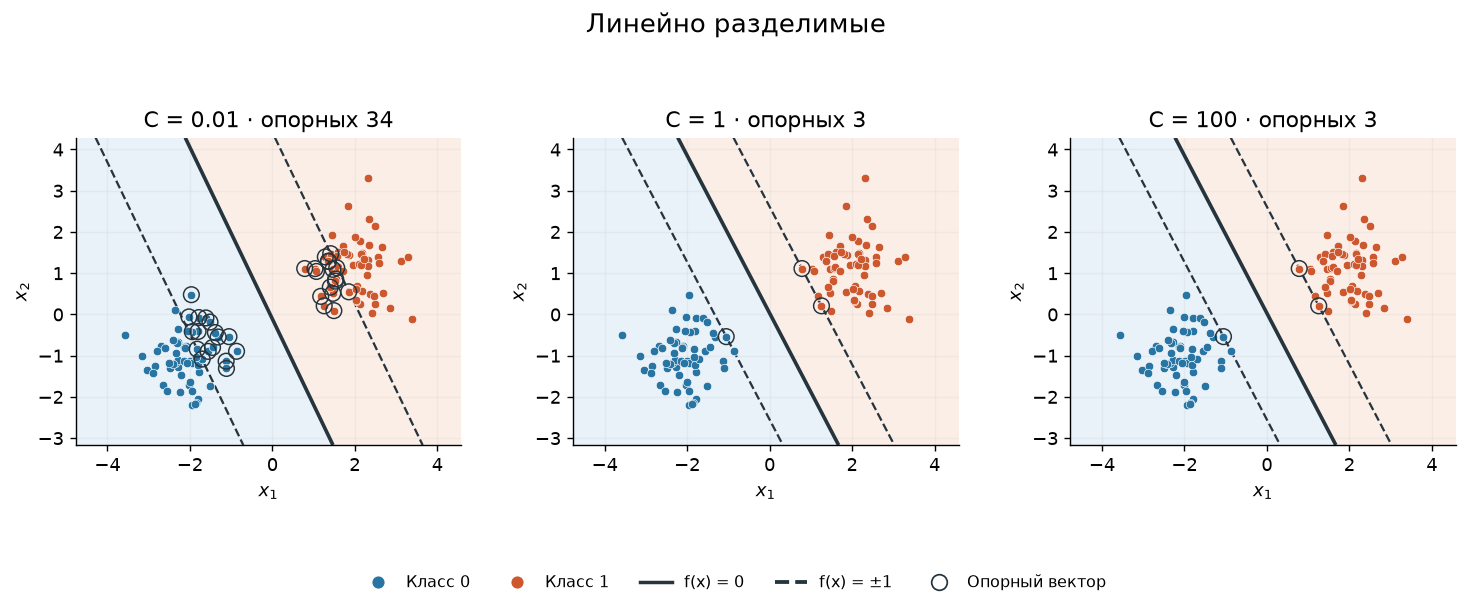

In [ ]:
draw_dataset("Линейно разделимые")

 При всех значениях $C$ получено ноль ошибок. При росте $C$ от 0.01 до 1 число опорных объектов уменьшается с 34 до 3, а ширина коридора — примерно с 3.92 до 2.39. Сначала многие правильно классифицированные точки находятся внутри широкого коридора. При большем штрафе границы коридора отодвигаются от этих точек. Начиная с $C=1$, в данном эксперименте параметры практически перестают меняться.

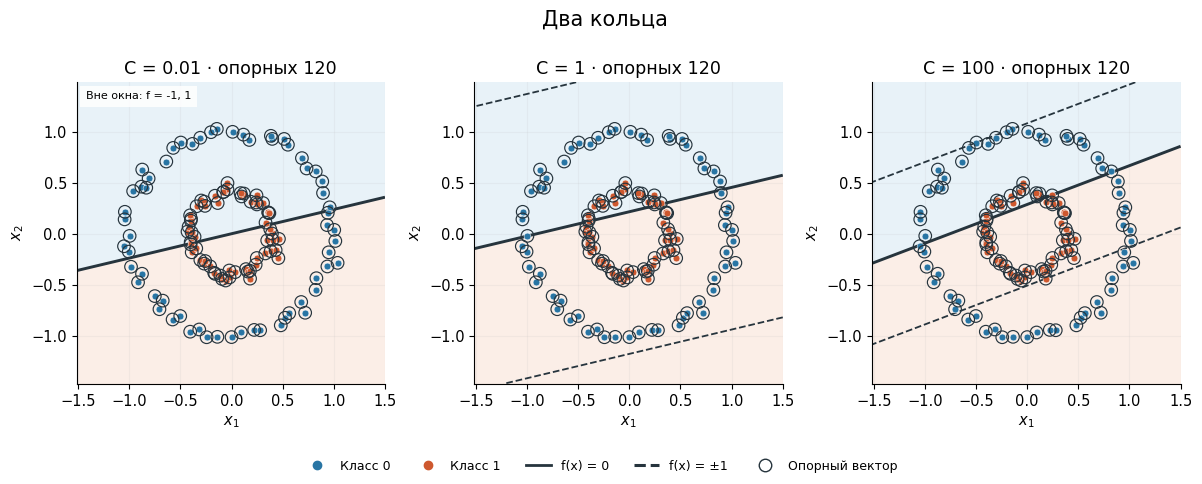

In [ ]:
draw_dataset("Два кольца")

Здесь прямая не может отделить внутреннее кольцо от внешнего. Число опорных объектов остаётся равным 120 на всей сетке. При $C=0.01$ ширина коридора около 270, поэтому его границы находятся далеко за пределами рисунка. Даже при $C=100$ модель допускает 50 ошибок из 120. Рост штрафа меняет прямую, но её геометрии недостаточно для этих классов.

На этой симметричной выборке при некоторых малых $C$ сдвиг $b$ может быть неединственным. Разные численные решения способны дать одинаковое значение цели SVM и разные прогнозы около границы. Приведённая таблица отражает конкретный запуск CVXOPT.

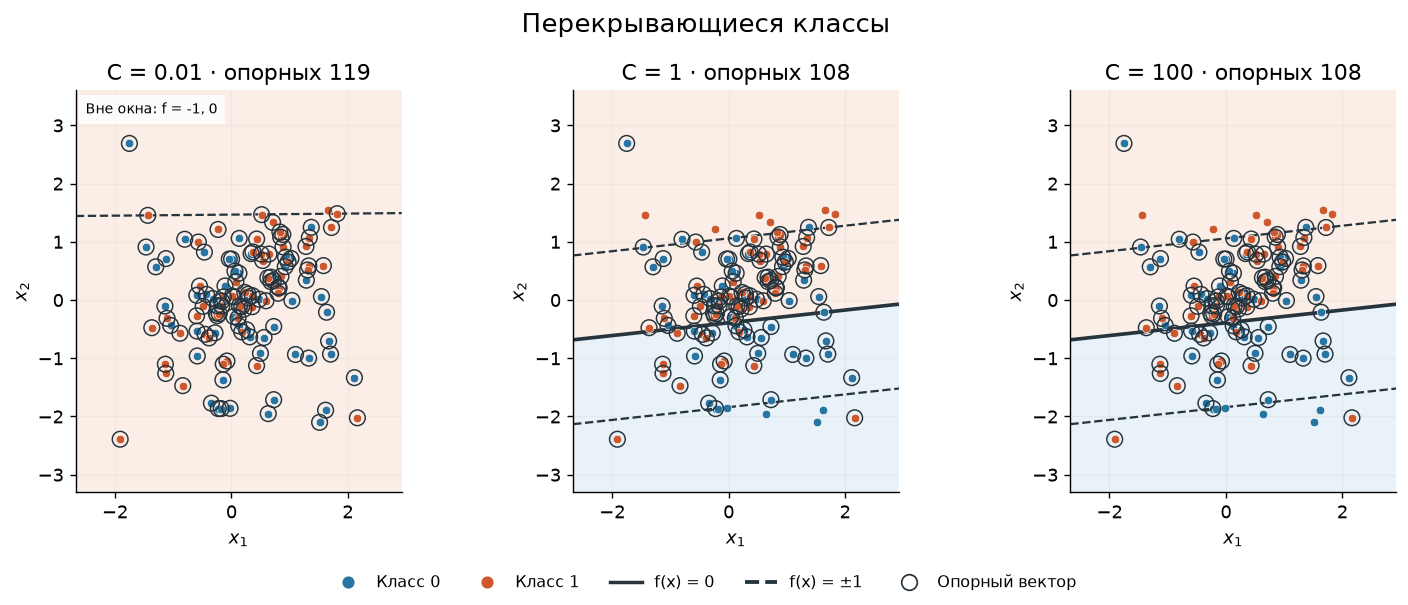

In [ ]:
draw_dataset("Перекрывающиеся классы")

Здесь число опорных объектов уменьшается с 119 до 108 и затем стабилизируется. Даже при большом $C$ много объектов остаётся внутри коридора или на неверной стороне. При $C\geq1$ получено 48 ошибок, то есть accuracy = 0.60. Сильное перекрытие и случайные метки не позволяют устранить ошибки одним увеличением штрафа.

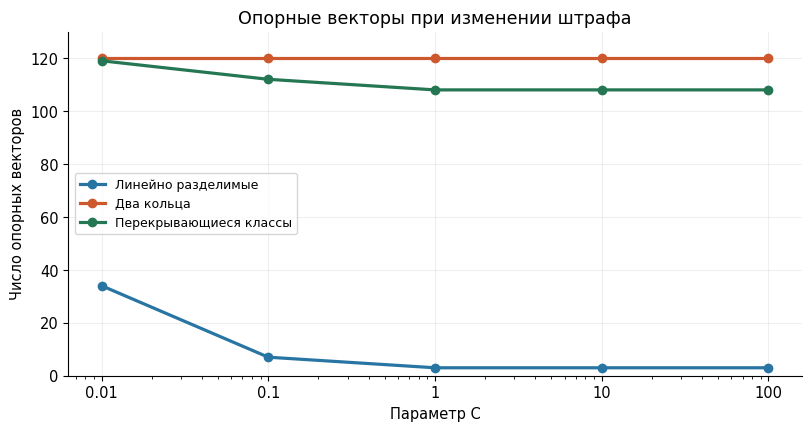

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
for name, color in zip(datasets, ["#2875a4", "#ce582e", "#247752"]):
    series = results[results["Выборка"] == name]
    ax.plot(series["C"], series["Опорных"], marker="o", linewidth=2.3,
            color=color, label=name)
ax.set(xscale="log", xlabel="Параметр C", ylabel="Число опорных векторов",
       title="Опорные векторы при изменении штрафа", ylim=(0, 130))
ax.set_xticks(C_values, labels=[f"{C:g}" for C in C_values])
ax.grid(alpha=0.2)
ax.legend(loc="center left", fontsize=9)
plt.show()

Ответ на вопрос: На линейно разделимой выборке растущий штраф уменьшает число точек, нарушающих границы коридора. На кольцах недостаток линейной модели сохраняет высокое число нарушений. На перекрывающейся выборке число опорных точек немного сокращается, затем сохраняется большой остаток. Наблюдаемая зависимость объясняется одновременно $C$ и геометрией данных. Универсального правила строгого уменьшения числа опорных векторов при каждом увеличении $C$ нет.

### 2.4. Квадратичная разделяющая поверхность

На тех же кольцах при $C=1$ заменяем два исходных признака пятью:
$$\phi(x_1,x_2)=(x_1,x_2,x_1^2,x_1x_2,x_2^2).$$
Тот же класс LinearSVM обучается в пятимерном пространстве. В исходных координатах его граница имеет вид
$$w_1x_1+w_2x_2+w_3x_1^2+w_4x_1x_2+w_5x_2^2+b=0.$$
Преобразование применяется и к обучающим данным, и к сетке для рисунка. Поэтому на плоскости отображается кривая. Уравнения $f(x)=\pm1$ также задают кривые, расстояние между ними в исходных координатах может меняться.

,Модель,C,Опорных,Ошибок,Accuracy
0,Линейная,1.0,120,55,0.541667
1,Квадратичная,1.0,20,0,1.000000


Коэффициенты для (x₁, x₂, x₁², x₁x₂, x₂²): [ 0.0264  0.0016 -2.7981  0.0869 -2.7237]
Сдвиг b: 1.5512


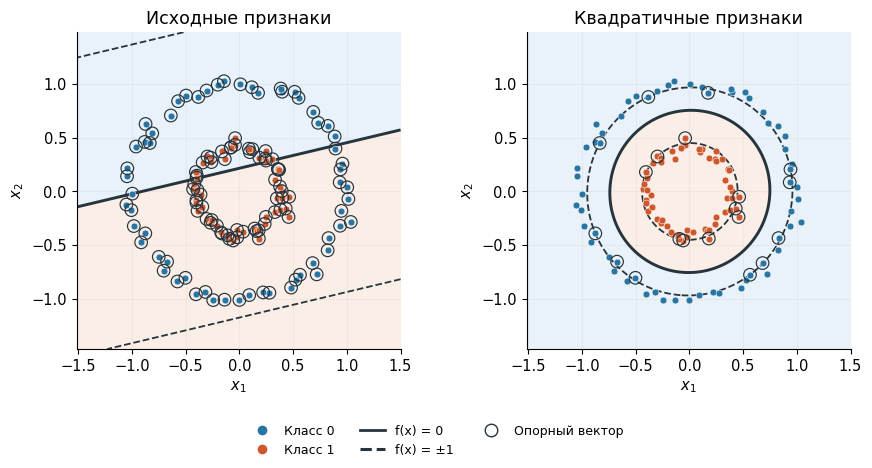

In [ ]:
def quadratic_features(X):
    x1, x2 = X[:, 0], X[:, 1]
    return np.column_stack([x1, x2, x1**2, x1*x2, x2**2])

X_ring, y_ring = datasets["Два кольца"]
quadratic_model = LinearSVM(C=1.0, transform=quadratic_features).fit(X_ring, y_ring)
linear_model = models["Два кольца", 1.0]
comparison = pd.DataFrame([
    {"Модель": label, "C": model.C, "Опорных": len(model.support_),
     "Ошибок": int(np.sum(model.predict(X_ring) != y_ring)),
     "Accuracy": model.score(X_ring, y_ring)}
    for label, model in [("Линейная", linear_model), ("Квадратичная", quadratic_model)]
])
display(comparison)
print("Коэффициенты для (x₁, x₂, x₁², x₁x₂, x₂²):",
      np.round(quadratic_model.weights_, 4))
print("Сдвиг b:", round(quadratic_model.bias_, 4))
fig, axes = plt.subplots(1, 2, figsize=(9, 4.8))
for ax, model, title in zip(axes, [linear_model, quadratic_model],
                           ["Исходные признаки", "Квадратичные признаки"]):
    draw_boundary(ax, model, X_ring, y_ring)
    ax.set_title(title)
fig.legend(handles=legend, loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.subplots_adjust(left=0.07, right=0.97, bottom=0.24, top=0.9, wspace=0.25)
plt.show()

 При одинаковом $C=1$ линейная модель допустила 55 ошибок, а модель с квадратичными признаками — ноль. Число опорных векторов уменьшилось со 120 до 20. Сумма квадратов координат позволяет различать расстояние до центра, поэтому найденная граница замыкается между кольцами.

## Выводы по 2 заданию

Линейный SVM успешно разделил два разнесённых облака. На кольцах увеличение $C$ не позволило построить подходящую прямую, а добавление квадратичных признаков решило эту проблему на обучающей выборке. При сильном перекрытии классов много объектов остаётся опорными даже при большом штрафе. Параметр $C$ регулирует компромисс между шириной коридора и нарушениями, а преобразование признаков меняет доступную форму границы. Эти два действия влияют на разные свойства модели.

Проверены статус оптимальности и выполнение ограничений всех обученных моделей. Прямой QP-солвер использован согласно [документации CVXOPT](https://cvxopt.org/userguide/coneprog.html#quadratic-programming), кольца сгенерированы с помощью [make_circles](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_circles.html).

# Часть 3. Двойственный SVM и ядра
## Задание 3
### 3.1. Сведение к QP

У каждого обучающего объекта появляется коэффициент $\alpha_i$. В двойственной задаче решаем
$$\max_\alpha\left(\mathbf1_N^\top\alpha-\frac12\alpha^\top P\alpha\right),
\quad 0\leq\alpha_i\leq C,\quad y^\top\alpha=0,$$
где $N$ — число объектов, $y_i\in\{-1,+1\}$ — метка, $C>0$ — штраф, $P_{ij}=y_i y_j k(x_i,x_j)$.

Для CVXOPT меняем знак цели и задаём
$$q=-\mathbf1_N,\quad G=\begin{pmatrix}-I_N\\I_N\end{pmatrix},
\quad h=\begin{pmatrix}0_N\\C\mathbf1_N\end{pmatrix},
\quad A=y^\top,\quad b_{\mathrm{eq}}=0.$$
Вектор оптимизации имеет длину $N$. $b_{\mathrm{eq}}$ — правая часть равенства солвера, а сдвиг классификатора $b$ вычисляется после решения.

**Ядро** задаёт скалярное произведение объектов в преобразованном пространстве:
$$k_{\mathrm{linear}}(x,x')=x^\top x',\quad
k_{\mathrm{poly}}(x,x')=(x^\top x'+1)^p,\quad
k_{\mathrm{RBF}}(x,x')=\exp(-\gamma\|x-x'\|^2).$$
Степень $p$ определяет доступные полиномиальные зависимости. При большом $\gamma$ RBF заметно связывает только близкие точки, поэтому граница может стать очень локальной. При малом $\gamma$ влияние объекта распространяется шире. Для любого из этих ядер прогноз имеет вид
$$f(x)=\sum_{i=1}^{N}\alpha_i y_i k(x,x_i)+b,\qquad
\widehat y=\operatorname{sign}f(x).$$
Объекты с $\alpha_i>0$ — опорные. В коде учитываем численную погрешность с помощью порога. Вектор явных нелинейных признаков вычислять не требуется. Для новых объектов нужна матрица ядра между новыми и обучающими точками, а обучающая матрица $K$ вычисляется один раз.

### Уточнение формулы сдвига из теории

Для soft-margin SVM равенство $y_i f(x_i)=1$ гарантировано для **свободных опорных объектов**, у которых $0<\alpha_i<C$. Поэтому используем
$$b=\frac{1}{|F|}\sum_{i\in F}\left(y_i-\sum_j\alpha_jy_j k(x_i,x_j)\right),
\qquad F=\{i:0<\alpha_i<C\}.$$
Вычисление среднего по всем опорным объектам, предложенное в п. 3.2 исходного ноутбука, в общем случае некорректно. При $\alpha_i=C$ объект может нарушать коридор, даже оставаясь правильно классифицированным.

Если свободных объектов нет, используем допустимый интервал для $b$ из условий оптимальности KKT. Пусть $g_i=\sum_j\alpha_jy_j k(x_i,x_j)$ и $r_i=y_i-g_i$.

| Коэффициент и класс | Ограничение на сдвиг |
|---|---|
| $\alpha_i=0,\ y_i=+1$ или $\alpha_i=C,\ y_i=-1$ | $b\geq r_i$ |
| $\alpha_i=0,\ y_i=-1$ или $\alpha_i=C,\ y_i=+1$ | $b\leq r_i$ |

Берём наибольшую нижнюю границу и наименьшую верхнюю, затем их среднее. Такой принцип восстановления сдвига используется и в [LIBSVM](https://github.com/cjlin1/libsvm/blob/master/svm.cpp) в процедуре calculate_rho.



### 3.2. Ядра и реализация DualSVM

In [20]:
from functools import partial
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted

def linear_kernel(X1, X2):
    return X1 @ X2.T

def poly_kernel(X1, X2, p=2):
    return (X1 @ X2.T + 1.0) ** p

def rbf_kernel(X1, X2, gamma=1.0):
    squared = (np.sum(X1**2, axis=1)[:, None]
               + np.sum(X2**2, axis=1)[None, :] - 2 * X1 @ X2.T)
    return np.exp(-gamma * np.maximum(squared, 0.0))

class DualSVM(ClassifierMixin, BaseEstimator):
    def __init__(self, C=1.0, kernel=None):
        self.C = C
        self.kernel = kernel

    def fit(self, X, y):
        X, y = check_X_y(X, y, dtype=float)
        if not np.isfinite(self.C) or self.C <= 0:
            raise ValueError("C должен быть положительным.")
        self.classes_ = np.unique(y)
        if self.classes_.size != 2:
            raise ValueError("Нужны ровно два класса.")
        self.n_features_in_ = X.shape[1]
        self.X_ = X.copy()
        self.y_ = np.where(y == self.classes_[1], 1.0, -1.0)
        self.kernel_ = linear_kernel if self.kernel is None else self.kernel
        N = len(X)
        K = np.asarray(self.kernel_(X, X), dtype=float)
        if K.shape != (N, N) or not np.all(np.isfinite(K)):
            raise ValueError("Ядро должно вернуть конечную матрицу N × N.")
        if not np.allclose(K, K.T):
            raise ValueError("Матрица ядра должна быть симметричной.")
        self.K_ = 0.5 * (K + K.T)
        P = np.outer(self.y_, self.y_) * self.K_
        q = -np.ones(N)
        G = np.vstack([-np.eye(N), np.eye(N)])
        h = np.r_[np.zeros(N), np.full(N, self.C)]
        A = self.y_[None, :]
        rhs = np.zeros(1)

        solution = solvers.qp(
            matrix(P), matrix(q), matrix(G), matrix(h), matrix(A), matrix(rhs),
            options={"show_progress": False, "abstol": 1e-8,
                     "reltol": 1e-8, "feastol": 1e-8, "maxiters": 150}
        )
        self.solver_status_ = solution["status"]
        if self.solver_status_ != "optimal":
            raise RuntimeError(f"QP не решена: {self.solver_status_}")
        self.alpha_ = np.array(solution["x"]).ravel()
        self.dual_coef_ = self.alpha_ * self.y_
        self.tol_ = min(1e-5, self.C * 1e-3)
        self.support_ = np.flatnonzero(self.alpha_ > self.tol_)
        self.support_vectors_ = self.X_[self.support_].copy()
        free = (self.alpha_ > self.tol_) & (self.alpha_ < self.C - self.tol_)
        self.free_support_ = np.flatnonzero(free)

        # g_i — оценка без сдвига. Для 0 < alpha_i < C верно y_i(g_i+b)=1.
        g = self.K_ @ self.dual_coef_
        residual = self.y_ - g
        if np.any(free):
            self.bias_ = float(residual[free].mean())
            self.bias_method_ = "свободные опорные"
        else:
            # Границы для b из условий KKT при alpha≈0 и alpha≈C.
            at_zero = self.alpha_ <= self.tol_
            at_C = self.alpha_ >= self.C - self.tol_
            lower_mask = (at_zero & (self.y_ > 0)) | (at_C & (self.y_ < 0))
            upper_mask = (at_zero & (self.y_ < 0)) | (at_C & (self.y_ > 0))
            lower = np.max(residual[lower_mask])
            upper = np.min(residual[upper_mask])
            if lower > upper + 1e-4:
                raise RuntimeError("Не удалось восстановить b с заданной точностью.")
            self.bias_ = float((lower + upper) / 2)
            self.bias_method_ = "середина интервала KKT"

        margins = self.y_ * (g + self.bias_)
        norm_squared = float(self.dual_coef_ @ g)
        self.primal_objective_ = 0.5 * norm_squared + self.C * np.maximum(0, 1-margins).sum()
        self.dual_objective_ = self.alpha_.sum() - 0.5 * norm_squared
        return self

    def decision_function(self, X):
        check_is_fitted(self, ["alpha_", "bias_"])
        X = check_array(X, dtype=float)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Число признаков отличается от обучения.")
        # Сохраняем и малые численные коэффициенты, чтобы не искажать сумму.
        return (self.kernel_(X, self.X_) @ self.dual_coef_ + self.bias_).ravel()

    def predict(self, X):
        positive = self.decision_function(X) >= 0
        return self.classes_[positive.astype(int)]

### 3.3. План экспериментов

Для первых трёх выборок используем те же генераторы и настройки, что в задании 2. В отличие от предыдущего эксперимента, теперь выделяем 30% точек для проверки, поэтому числа ошибок напрямую с заданием 2 не сравниваем.

| Выборка | Параметры генерации | Обучение / проверка |
|---|---|---:|
| Облака | 120 точек, центры $(-2,-1),(2,1)$, стандартное отклонение 0.6 | 84 / 36 |
| Кольца | 120 точек, factor=0.4, noise=0.04 | 84 / 36 |
| Перекрытие | 120 точек, 2 информативных признака, один кластер на класс, class_sep=0.35, flip_y=0.25 | 84 / 36 |
| Полумесяцы | 300 точек, noise=0.2 | 150 / 150 |

У всех генераторов и разбиений random_state=42. Разбиение стратифицировано по классам. StandardScaler обучается только на обучающей части и затем применяется к обеим частям. Это выравнивает масштабы координат без использования проверочных данных при обучении.

Сначала при $C=1$ сравниваем линейное, полиномиальные ядра степеней 2 и 3 и RBF с $\gamma=1$. Затем на полумесяцах перебираем:
- полиномиальное ядро — $p\in\{2,3,5\}$ и $C\in\{0.01,0.1,1,10,100\}$;
- RBF — те же значения $C$ и $\gamma\in\{0.01,0.1,1,10,100\}$.

Используем accuracy — долю верных прогнозов. Проверочная часть служит для исследования гиперпараметров. Её результаты являются оценкой на одном разбиении, для независимой итоговой оценки выбранной модели потребовалась бы отдельная тестовая выборка.

### 3.4. Данные, разбиение и обучение моделей

In [21]:
from sklearn.datasets import make_blobs, make_circles, make_classification, make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

raw = {
    "Облака": make_blobs(n_samples=120, centers=[(-2,-1),(2,1)],
                         cluster_std=0.6, random_state=42),
    "Кольца": make_circles(n_samples=120, factor=0.4, noise=0.04, random_state=42),
    "Перекрытие": make_classification(
        n_samples=120, n_features=2, n_informative=2, n_redundant=0,
        n_clusters_per_class=1, class_sep=0.35, flip_y=0.25, random_state=42),
    "Полумесяцы": make_moons(n_samples=300, noise=0.2, random_state=42),
}
datasets = {}
for name, (X, y) in raw.items():
    fraction = 0.5 if name == "Полумесяцы" else 0.3
    Xt, Xv, yt, yv = train_test_split(
        X, y, test_size=fraction, stratify=y, random_state=42)
    scaler = StandardScaler().fit(Xt)
    datasets[name] = (scaler.transform(Xt), scaler.transform(Xv), yt, yv)

models = {}
records = []
def train(name, label, C, kernel, degree=None, gamma=None):
    Xt, Xv, yt, yv = datasets[name]
    model = DualSVM(C=C, kernel=kernel).fit(Xt, yt)
    assert model.alpha_.min() >= -1e-6
    assert model.alpha_.max() <= C + 1e-6
    assert abs(model.alpha_ @ model.y_) < 1e-5
    relative_gap = abs(model.primal_objective_ - model.dual_objective_) / max(1., abs(model.primal_objective_))
    assert relative_gap < 1e-3, (name, label, C, relative_gap)
    models[name, label, C] = model
    row = {"Выборка": name, "Ядро": label, "C": C, "p": degree, "gamma": gamma,
           "Обучение": model.score(Xt, yt), "Проверка": model.score(Xv, yv),
           "Опорных": len(model.support_), "Разрыв целей": relative_gap}
    records.append(row)
    return model

for name in datasets:
    train(name, "Линейное", 1., linear_kernel)
    train(name, "Poly p=2", 1., partial(poly_kernel, p=2), degree=2)
    train(name, "Poly p=3", 1., partial(poly_kernel, p=3), degree=3)
    train(name, "RBF gamma=1", 1., partial(rbf_kernel, gamma=1), gamma=1)

C_values = [0.01, 0.1, 1., 10., 100.]
degrees = [2, 3, 5]
gammas = [0.01, 0.1, 1., 10., 100.]
for C in C_values:
    for p in degrees:
        label = f"Poly p={p}"
        if ("Полумесяцы", label, C) not in models:
            train("Полумесяцы", label, C, partial(poly_kernel, p=p), degree=p)
    for gamma in gammas:
        label = f"RBF gamma={gamma:g}"
        if ("Полумесяцы", label, C) not in models:
            train("Полумесяцы", label, C, partial(rbf_kernel, gamma=gamma), gamma=gamma)
results = pd.DataFrame(records)
print(f"Успешно обучено моделей: {len(results)}.")
display(results[results["C"] == 1][["Выборка","Ядро","Обучение","Проверка","Опорных"]].round(3))

Успешно обучено моделей: 53.


,Выборка,Ядро,Обучение,Проверка,Опорных
0,Облака,Линейное,1.000,1.000,3
1,Облака,Poly p=2,1.000,1.000,4
2,Облака,Poly p=3,1.000,1.000,4
3,Облака,RBF gamma=1,1.000,1.000,10
4,Кольца,Линейное,0.643,0.472,80
5,Кольца,Poly p=2,1.000,1.000,5
6,Кольца,Poly p=3,1.000,1.000,9
7,Кольца,RBF gamma=1,1.000,1.000,20
8,Перекрытие,Линейное,0.607,0.611,76
9,Перекрытие,Poly p=2,0.690,0.611,63


### 3.5. Сравнение ядер на трёх выборках

На графиках кружки — обучающие точки, треугольники — проверочные, цвет означает истинный класс. Чёрные окружности выделяют опорные обучающие объекты. Фон — предсказанный класс. Сплошная линия задаёт $f(x)=0$, пунктир — $f(x)=\pm1$. В исходных координатах расстояние между нелинейными границами коридора может быть непостоянным.

In [ ]:
#@title Функции построения границ и таблиц качества
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap

palette = ["#2875a4", "#ce582e"]
background = ListedColormap(["#e8f2f8", "#fbeee7"])
legend = [
    Line2D([], [], marker="o", linestyle="", color=palette[0], label="Класс 0"),
    Line2D([], [], marker="o", linestyle="", color=palette[1], label="Класс 1"),
    Line2D([], [], marker="^", linestyle="", color="#53616b", label="Проверочная точка"),
    Line2D([], [], color="#26343d", label="f(x) = 0"),
    Line2D([], [], color="#26343d", linestyle="--", label="f(x) = ±1"),
    Line2D([], [], color="#26343d", marker="o", markerfacecolor="none",
           linestyle="", markersize=9, label="Опорный вектор"),
]

def boundary(ax, name, model):
    Xt, Xv, yt, yv = datasets[name]
    both = np.vstack([Xt, Xv])
    padding = 0.12 * np.ptp(both, axis=0) + 0.1
    low, high = both.min(axis=0)-padding, both.max(axis=0)+padding
    xx, yy = np.meshgrid(np.linspace(low[0],high[0],190),
                         np.linspace(low[1],high[1],190))
    z = model.decision_function(np.c_[xx.ravel(),yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx,yy,z>=0,levels=[-0.5,0.5,1.5],cmap=background)
    for level in [-1,0,1]:
        if z.min() <= level <= z.max():
            ax.contour(xx,yy,z,levels=[level],colors="#26343d",
                       linestyles="-" if level==0 else "--",
                       linewidths=1.8 if level==0 else 1.1)
    for cls,color in enumerate(palette):
        ax.scatter(*Xt[yt==cls].T,s=22,c=color,edgecolors="white",linewidths=0.4,zorder=3)
        ax.scatter(*Xv[yv==cls].T,s=23,c=color,marker="^",
                   edgecolors="white",linewidths=0.4,zorder=3)
    ax.scatter(*model.support_vectors_.T,s=68,facecolors="none",
               edgecolors="#26343d",linewidths=0.8,zorder=4)
    ax.set(xlim=(low[0],high[0]),ylim=(low[1],high[1]),
           xlabel="$x_1$ после масштабирования",ylabel="$x_2$",aspect="equal")
    ax.grid(alpha=0.12)

def compare_boundaries(name, configurations):
    fig,axes = plt.subplots(1,len(configurations),figsize=(3.6*len(configurations),4.9))
    for ax,(label,C) in zip(axes,configurations):
        model=models[name,label,C]
        boundary(ax,name,model)
        _,Xv,_,yv=datasets[name]
        ax.set_title(f"{label}, C={C:g}\nПроверка {model.score(Xv,yv):.1%}",fontsize=10)
    fig.suptitle(name,fontsize=15)
    fig.legend(handles=legend,loc="lower center",ncol=3,frameon=False,fontsize=9)
    fig.subplots_adjust(left=0.065,right=0.985,bottom=0.24,top=0.80,wspace=0.30)
    plt.show()

def heatmaps(data, parameter, values, title):
    fig,axes=plt.subplots(1,2,figsize=(10.4,4.8),layout="constrained")
    for ax,metric in zip(axes,["Обучение","Проверка"]):
        table=data.pivot(index="C",columns=parameter,values=metric).reindex(
            index=C_values,columns=values)
        image=ax.imshow(table.to_numpy(),vmin=0.65,vmax=1,cmap="YlGnBu",aspect="auto")
        for i in range(len(C_values)):
            for j in range(len(values)):
                val=table.iloc[i,j]
                ax.text(j,i,f"{val:.2f}",ha="center",va="center",fontsize=10,
                        color="white" if val>0.88 else "#152530")
        ax.set_xticks(range(len(values)),labels=[f"{v:g}" for v in values])
        ax.set_yticks(range(len(C_values)),labels=[f"{v:g}" for v in C_values])
        ax.set(xlabel=parameter,ylabel="C",title=metric)
    fig.colorbar(image,ax=axes,label="Доля правильных ответов",shrink=0.85)
    fig.suptitle(title,fontsize=14)
    plt.show()

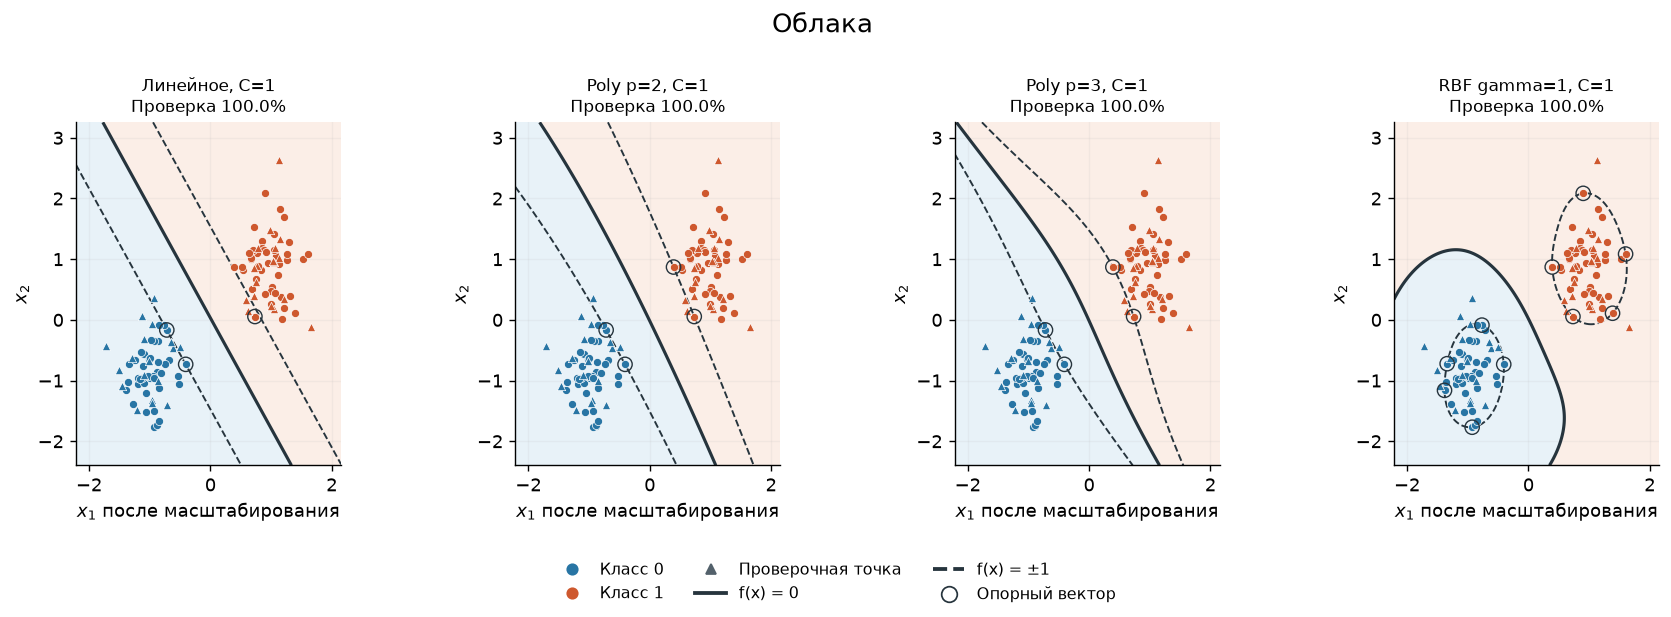

In [ ]:
baseline = [("Линейное",1.),("Poly p=2",1.),("Poly p=3",1.),("RBF gamma=1",1.)]
compare_boundaries("Облака", baseline)

Пояснение к облакам: все четыре ядра дали 100% верных ответов на обучении и проверке. Линейной модели достаточно для этой геометрии. У неё 3 опорных вектора, у RBF — 10, при одинаковом качестве на данном разбиении.

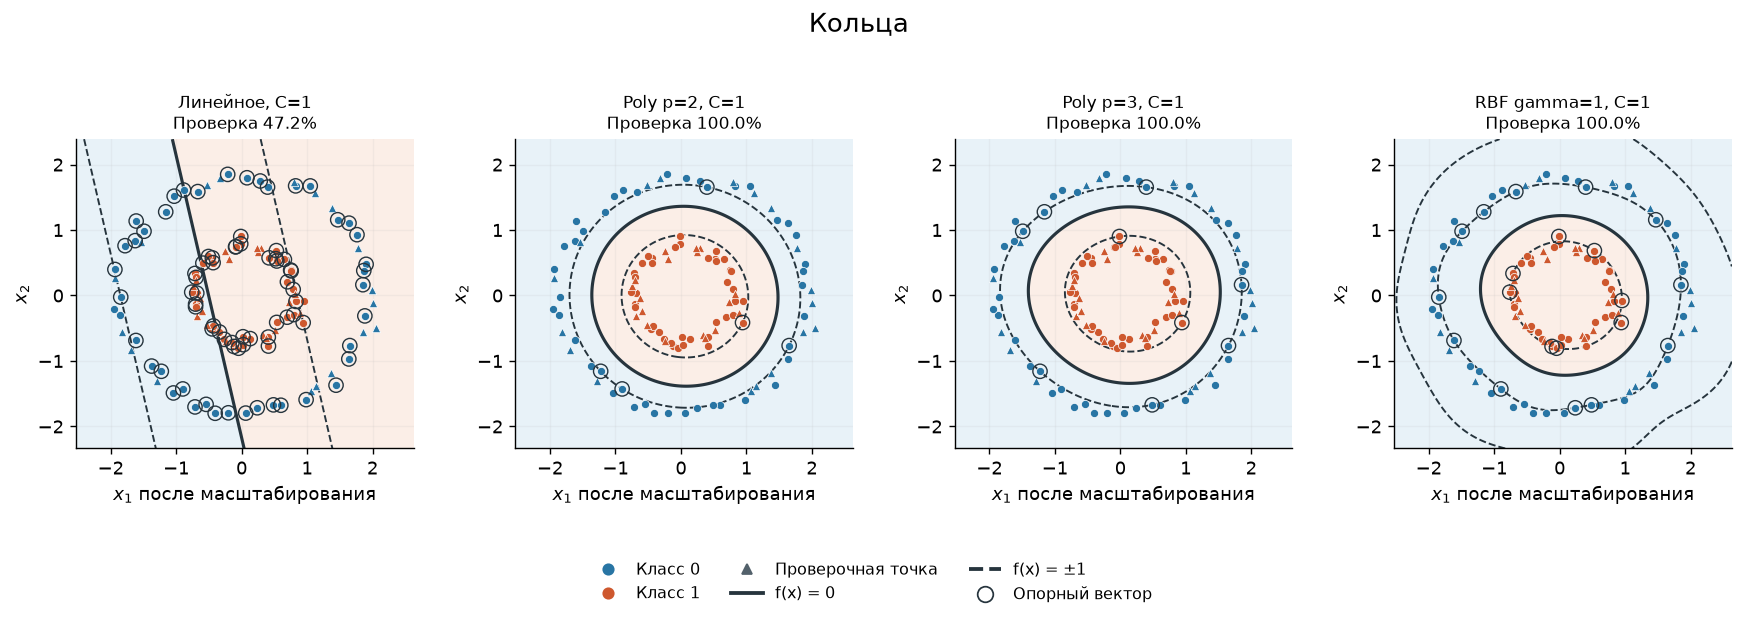

In [ ]:
compare_boundaries("Кольца", baseline)

Пояснение по кольцам: линейная модель дала 47.2% на проверке. Полиномиальные ядра степеней 2 и 3 и RBF получили 100%. Нелинейные границы замыкаются между кольцами, что позволяет отделить внутренний класс от внешнего.

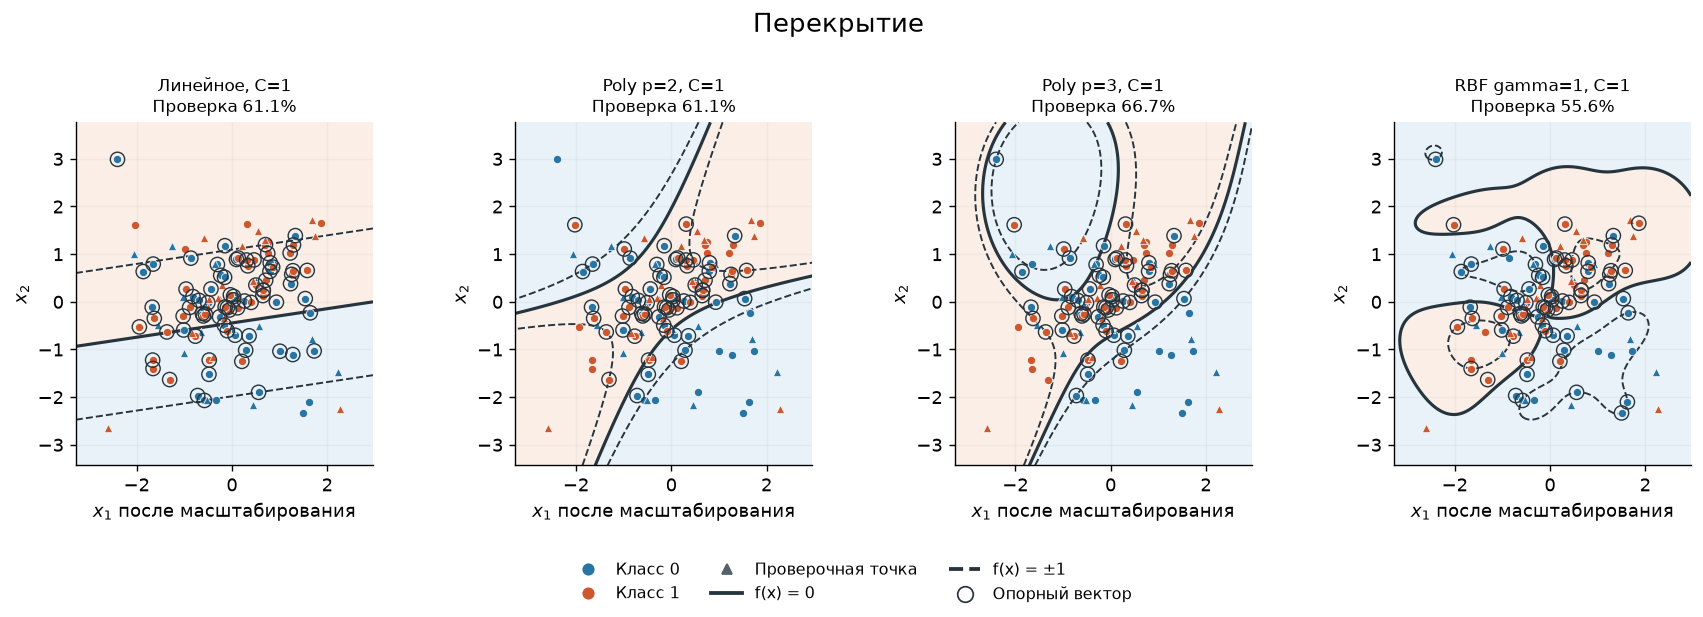

In [ ]:
compare_boundaries("Перекрытие", baseline)

Пояснение по перекрытиям: на проверке получены 61.1% для линейного ядра, 61.1% для степени 2, 66.7% для степени 3 и 55.6% для RBF. У RBF качество на обучении выше — 71.4%, но на новых точках в этом разбиении хуже. Более гибкая модель может подстраиваться под шум и особенности обучающих объектов. Проверочных объектов здесь всего 36, поэтому различие в один ответ меняет accuracy примерно на 2.8 процентного пункта.

### 3.6. Сравнение на полумесяцах

При одинаковом C=1 сравниваем линейное ядро, полиномиальное степени 3 и RBF с gamma=1. Степень 3 выбрана как пример криволинейной границы. В следующем разделе отдельно исследуются и другие степени.

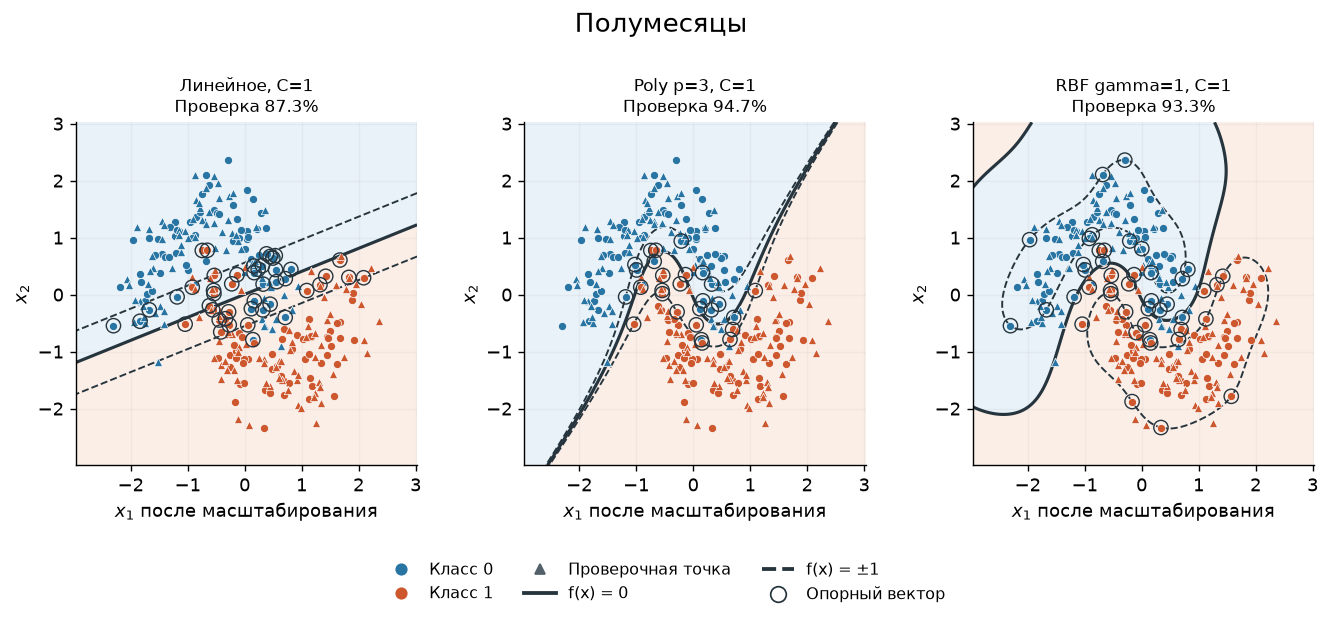

In [ ]:
compare_boundaries("Полумесяцы", [("Линейное",1.),("Poly p=3",1.),("RBF gamma=1",1.)])

Пояснение к полумесяцам: линейное ядро дало 87.3% на проверке, полиномиальное степени 3 — 94.7%, RBF — 93.3%. Криволинейные границы лучше повторяют форму классов. При этом полиномиальная модель использует 28 опорных объектов, RBF — 44. Шум делает разделение несовершенным даже при подходящей форме границы.

### 3.7. Как влияют C и степень полиномиального ядра?

На двух тепловых картах приведены доли верных ответов на обучении и проверке. Строки соответствуют $C$, столбцы — степени $p$. Чем темнее ячейка, тем выше точность.

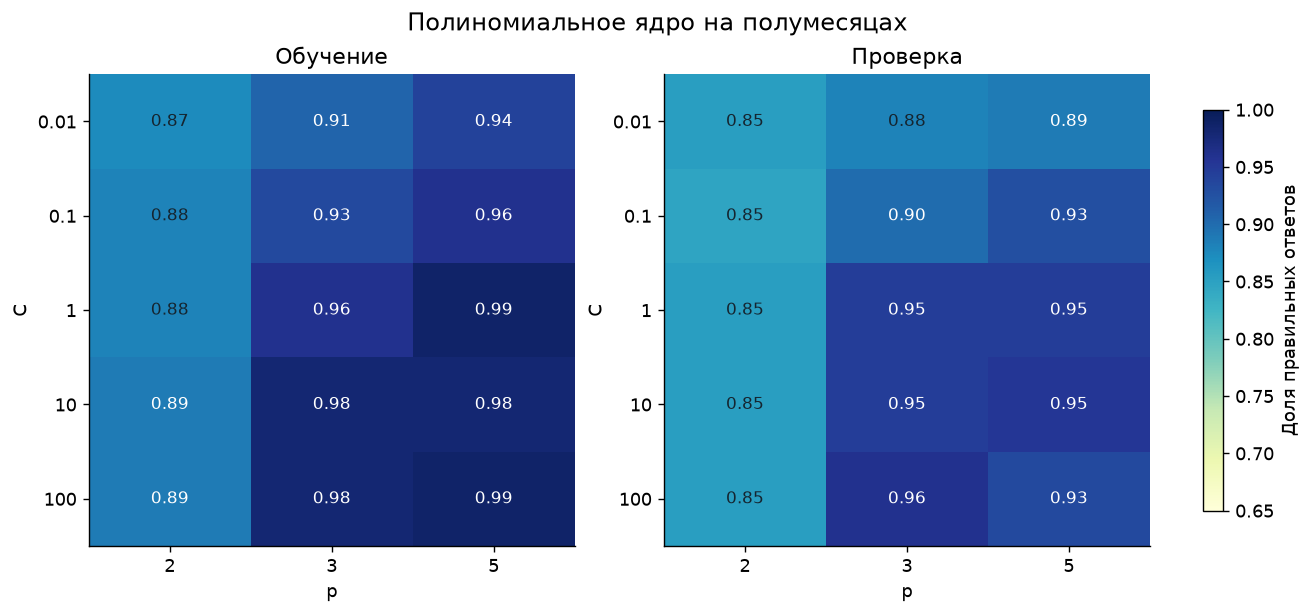

In [ ]:
moon = results[results["Выборка"] == "Полумесяцы"]
polynomial = moon[moon["p"].notna()]
heatmaps(polynomial, "p", degrees, "Полиномиальное ядро на полумесяцах")

Рост $C$ увеличивает штраф за нарушения, а рост $p$ расширяет набор доступных нелинейных зависимостей. При $p=2$ качество на проверке около 85% и почти не растёт с $C$: этой формы границы недостаточно для полумесяцев.

При $C=1$ переход от $p=2$ к $p=3$ повышает качество с 85.3% до 94.7%. Степень 5 при том же $C$ тоже даёт 94.7%, хотя качество на обучении увеличивается с 96.0% до 98.7%.

Увеличение обоих параметров не гарантирует улучшения. При $p=5$ рост $C$ с 10 до 100 повышает качество на обучении с 98.0% до 98.7%, но снижает проверочное с 95.3% до 93.3%. Это наблюдение согласуется с подстройкой более гибкой модели под особенности обучающей части. Кроме того, большое $p$ может ухудшать численную обусловленность матрицы ядра.

### 3.8. Как влияют C и gamma у RBF?

Параметры перебираются по логарифмической сетке: соседние значения отличаются в 10 раз. На обеих картах использована одинаковая цветовая шкала. Строки — $C$, столбцы — $\gamma$.

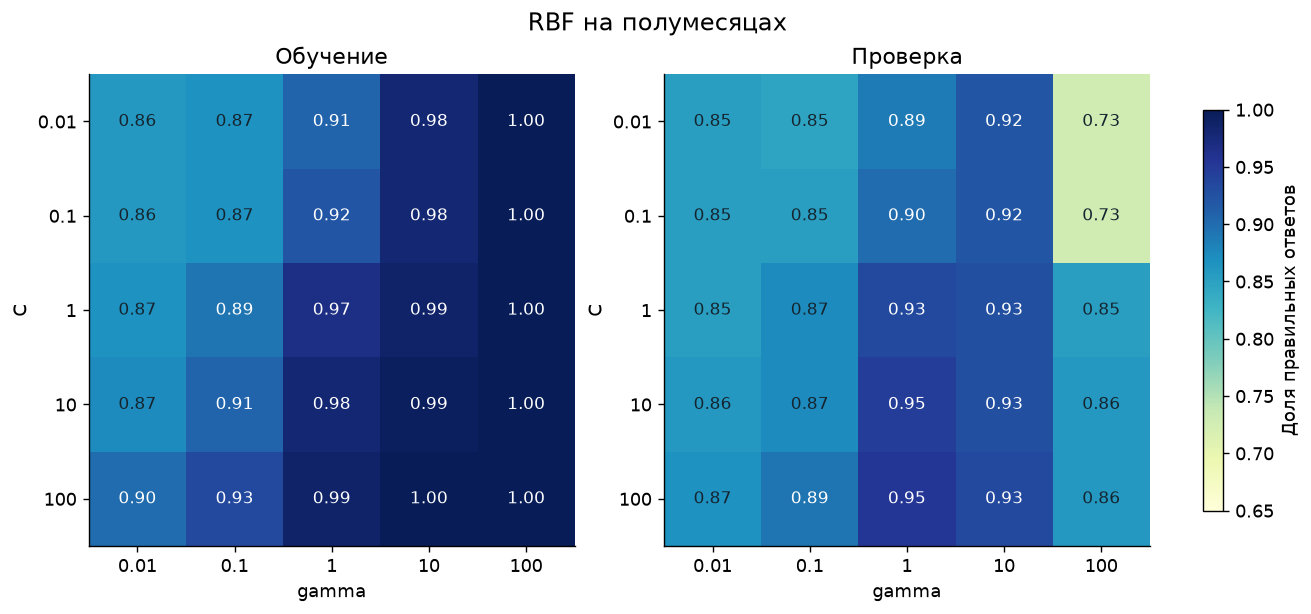

In [ ]:
radial = moon[moon["gamma"].notna()]
heatmaps(radial, "gamma", gammas, "RBF на полумесяцах")

Слишком грубая модель: При $\gamma=0.01$ влияние каждого объекта широко распределено по пространству. На этой сетке проверочная точность остаётся в пределах 85.3–86.7%, и модель недостаточно учитывает изгиб полумесяцев. При $C=0.01$ и $\gamma=0.01$ качество составляет 86.0% на обучении и 85.3% на проверке.

Умеренные значения: При $\gamma=1$ и $C=10$ получено 98.0% на обучении и 94.7% на проверке. Модель формирует плавную нелинейную границу, соответствующую форме данных.

Слишком локальная модель: При $\gamma=100$ влияние отдельной точки очень узкое. Для $C=100$ качество на обучении равно 100%, а на проверке — 86.0%. Разрыв показывает, что точное воспроизведение обучающих меток не обеспечивает столь же хорошего качества на новых объектах.

В этой серии большое $\gamma$ вызывает большой разрыв даже при малом $C$. Например, при $C=0.01,\gamma=100$ получено 100% на обучении и 72.7% на проверке. Значит, оба параметра нужно оценивать совместно, а влияние $C$ нельзя свести к универсальному правилу «малое значение всегда устраняет переобучение».

Ниже показаны три характерных сочетания параметров.

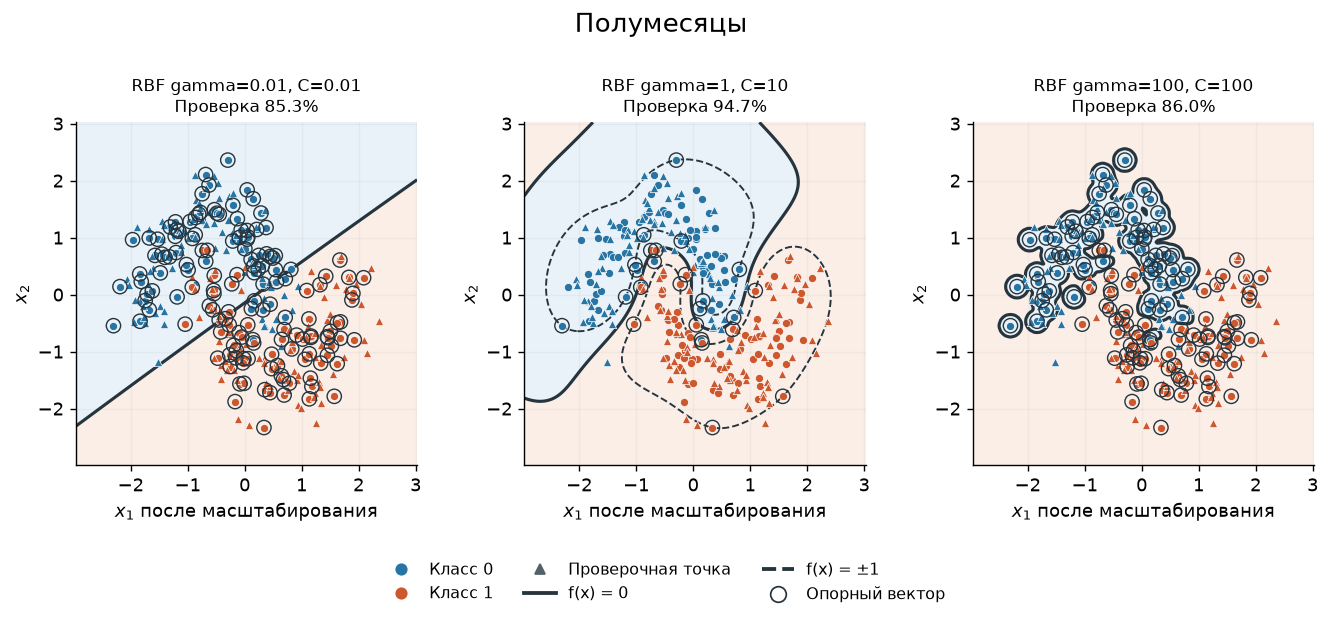

In [ ]:
compare_boundaries("Полумесяцы", [("RBF gamma=0.01",0.01),("RBF gamma=1",10.),("RBF gamma=100",100.)])

 Слева модель задаёт слишком грубое разделение. В середине граница следует изгибу полумесяцев. Справа появляются небольшие области вокруг отдельных обучающих объектов и неровная граница, а качество на отложенных точках снижается.

### 3.9. Проверка реализации

Для каждой из 53 моделей проверены ограничения на alpha, равенство yᵀalpha=0 и близость значений прямой и двойственной целей. Ниже дополнительно проверяется случай без свободных опорных векторов и сравниваются прогнозы с SVC при линейном, полиномиальном и RBF-ядрах на полумесяцах.

In [ ]:
from sklearn.svm import SVC

Xt, Xv, yt, yv = datasets["Полумесяцы"]
checks = []
for label in ["Линейное","Poly p=3","RBF gamma=1"]:
    own = models["Полумесяцы",label,1.]
    reference = SVC(C=1.,kernel=own.kernel_,tol=1e-8).fit(Xt,yt)
    agreement = np.mean(reference.predict(Xv)==own.predict(Xv))
    assert agreement == 1.0
    checks.append({"Ядро":label,"Совпадение прогнозов с SVC":agreement})
display(pd.DataFrame(checks))
tiny = DualSVM(C=0.01).fit(np.array([[-1.],[1.]]),np.array([-1,1]))
assert len(tiny.free_support_) == 0
assert tiny.bias_method_ == "середина интервала KKT"
assert np.allclose(tiny.bias_,0,atol=1e-6)
assert np.array_equal(tiny.predict(np.array([[-1.],[1.]])),[-1,1])
print("Случай без свободных опорных векторов проверен.")
print("Максимальный относительный разрыв целей:", results["Разрыв целей"].max())

Случай без свободных опорных векторов проверен.
Максимальный относительный разрыв целей: 2.267863415824167e-05


,Ядро,Совпадение прогнозов с SVC
0,Линейное,1.0
1,Poly p=3,1.0
2,RBF gamma=1,1.0


## Выводы по 3 заданию

Двойственная форма позволяет менять ядро при сохранении одной QP-постановки. Линейного ядра достаточно для разнесённых облаков, а кольца и полумесяцы требуют нелинейной границы. Полиномиальная степень и параметр RBF $\gamma$ влияют на форму и локальность границы, а $C$ регулирует штраф за нарушения. Большая гибкость может улучшить качество, но при избыточной подстройке разрыв между обучением и проверкой растёт. Поэтому гиперпараметры следует сравнивать по отложенным данным или кросс-валидации.


# Часть 4. SVM на реальных данных
## Теоретическое введение

Для каждого пациента задан вектор признаков $x_i$ и метка $y_i\in\{-1,+1\}$. Значение $+1$ означает наличие заболевания в исходных данных. Линейная модель использует оценку $f(x)=w^\top x+b$, а ядровая — $f(x)=\sum_i\alpha_i y_i k(x_i,x)+b$. Знак оценки определяет прогноз класса.

Параметр $C>0$ задаёт штраф за нарушения отступа. В RBF-ядре
$$k(x,z)=\exp(-\gamma\|x-z\|^2)$$
параметр $\gamma>0$ определяет, насколько быстро уменьшается сходство при удалении объектов друг от друга.

Качество измеряю долей правильных ответов:
$$\operatorname{accuracy}=\frac1m\sum_{i=1}^m
\mathbb I[\widehat y_i=y_i],$$
где $m$ — число проверяемых объектов, $\widehat y_i$ — прогноз, а индикатор $\mathbb I$ равен единице при верном ответе.

Для стандартизации каждого признака использую
$$\widetilde x_j=\frac{x_j-\mu_j}{s_j}.$$
Здесь $\mu_j$ и $s_j$ — среднее и стандартное отклонение признака на обучающей части. Одинаковые параметры преобразования применяются к проверочным объектам. Так расстояния и регуляризация модели меньше зависят от единиц измерения.

## Задание 4.
### 4.1. Описание эксперимента

Я использовал предоставленный файл heart.csv: 303 объекта, 13 признаков и столбец диагноза num. Источник и расшифровка признаков — [Heart Disease, UCI](https://archive.ics.uci.edu/dataset/45/heart+disease), Janosi et al., DOI 10.24432/C52P4X, лицензия CC BY 4.0.

После подготовки выделяю 20% объектов в тест с сохранением долей классов. Фиксирую random_state=42. Параметры выбираю по средней accuracy на пяти стратифицированных фолдах **внутри train**. На каждом фолде скейлер обучается заново только на его обучающей части.

Для своей LinearSVM перебираю $C=10^{-3},10^{-2},\ldots,10^5$. Для своей DualSVM использую RBF и сетку $C\in\{0.01,0.1,1,10,100\}$, $\gamma\in\{0.001,0.01,0.1,1,10\}$. При равенстве среднего качества выбираю меньшее $C$, затем меньшее $\gamma$. При равном качестве двух семейств предпочитаю линейную модель как более простую.

Train и test accuracy для всей сетки показываю по условию задания, но правило выбора параметров использует только CV. Тестовые результаты служат для оценки уже выбранных моделей и описания эксперимента.

### 4.2. Загрузка и подготовка данных

1. Я задал названия столбцов, поскольку в файле нет заголовка, и учёл "?" как пропуски.
2. Удалил строки с пропусками: их шесть, то есть 1.98% исходных данных. Это простая обработка при небольшой потере объёма. Распределение удалённых наблюдений может отличаться, поэтому выводы относятся к оставшимся полным записям.
3. Преобразовал num: ноль соответствует $-1$, значения 1–4 — $+1$. Сам num исключил из признаков.
4. Закодировал cp, restecg, slope, thal через pd.get_dummies. Наборы категорий заранее заданы документацией. Все dummy-столбцы сохранены; регуляризация весов позволяет использовать такое кодирование. Бинарные sex, fbs, exang оставил без перекодирования.
5. Разбил данные на train/test и обучил StandardScaler на train. В таблице ниже показаны и исходные строки, и строки после полного преобразования. Последний столбец y приведён для просмотра и в обучение как признак не передаётся.

In [23]:
#@title 4.3. Встроенная копия исходного heart.csv
import base64, zlib, hashlib
HEART_CSV=zlib.decompress(base64.b64decode(
'eJyNnEmWWzsIhue1lhwfdbcbZf+7emUhAR+S/TKoJHaMkWh+2ltnfaU/ef604/fPUud75f33kX7/TP1V/VPHv8/33z/nNT7Y3n+f/UP3qR//fS/d+vVHf6eOnxKISycpjyfur+QcZ3/n/dOpfuok7ketnUQP+v7J9zX+VX85V/33+9gtey5CnJp/7yrza17tTwbxcXrhyLHr6Tlft766A/E5v7ffuXXi8/acz6QEpwhqCu3nuDxx51yP5jmfU3Hplzhwnv/VnMBw5za//n3nMj59dVUdIJZjJxrJofrIKm1R1XEtxPmZcuivmglMOJuFHbAm4fzg2Mfkln/NcxIHVXkjgfravGcaFpYH5/LT2qrnc/ISPeOVu/Mv5+I5d2vKz+M+lk+TwBGJYduHfPwG56Zco57bdLjOM9Or+FWThVPVvLPTcyWx3bfsOM+XQ9rX4YndVy3E5upKfNKrsr5abHseO9udM3y82SfuaCReHCLtcsO2z+I/sRIHI7lhnk5g5JyNWATWAa4Qhgy3irJ5q6r+nPNAzp8TnKUWPVsDerYfRcpqx87Qs5PK+UlgRlwboPeCd1NV52uRdoGes0ngjLgNGBJiRS0aSXZeNYghsCzWfL2cwLL3+HmFIe3n5Y69c4zDON/6JePO5NwhtXrRZP3EDDdTVcVsuyrnWuFVB6CBFvZ4zlWCOyOGedWBOycDQOfPlQBoiBajpAKrQ5LyKUpGI6Gei3wcqiqTqIRj1xBuxEguOEb+BPq/Ajs8cfegeuDO6lVvAPRR8tdIJj4Ybhe9ihBfSpyCV51Tp+7YZb5n5pkccX1Nf1bbNvOUcENpewszPavPGF7VBA92saqBezILc3d28n2/Z2nFgtvzpWFYrQmnwSUccUTPzrMEYhPfAVX9AiBUJWDAWFVM6/HYB/zZ6dnM01K6E+bZTM/mzy1PsygQ2Ewfs3Gu7qUILD8ktlhVvma9qVv6Ayc8o0sa5xOOEVwy6VW8kWyQpJmqHqiKPuY4xzysMlb19+7PSLKLkuTlMoOmnHfZUI/MlpOIEC1rIRhkMxLTc0DP01sYiVv2nId5Fs95C/rh2BKfO+hfMM/D/FlKI2dhiiJGnGnbx2sVmCMO/pzgVS2i5zz2r56nZKt9kKCPKEnbVjAQVd392MyGDHYL0HMITDn3KFnTFKLI3mw7Wlgwkv4BGqSKb62raJ5SfN/QswqsjPSxrMRmYflGxDg81oTcE0YiGFbBWYHK4/YoUJBWdOHUshZq8vWmKqfnyNmykOQK0RpyzxzQs9+vMEa0L8U3Gw6d+ICenUsWSLtK5U49l9MDoJZ3OWgqB/CU+qSh6nfufCrYSUoSwNMwX4mJw166QV4S27UiEc4m+kVesM4hLxy7mVPdEf8QrSVvTSS2UHUEIGERK7DdYNq3eWSBjUQsGAkg7pwnN39nUXODqjoKlHBsn3cEztN8XLQ52WMxA2uBuCKTEoEVhGxFhk2cQzJ0y50RODUe5ZCSVGtWWGpdC2DbFXRL4b7WJ6V+UlU8dmMXr8P2Ads+zo/EKm2JcxvMz8eG+O+qqE5aoajz86Fp2a6rZFo2RIpV6DnRz/XwNNmODhlNhN1Dcc9gX/PG50j/ZpRzAObLOeKu1eY3QuTQst5ZmroNxC57jg2DE4qSKvTAnb80DNQ4XWQ/oNczO6KQwSFQCfBW5I5LQhKCs0pbcITw50yV/enoU1VwBAI7YqDawJ/cWRpDENj92S2IYFlCJODv3rnFACF20vo5mJBo63GjKvan38Q1MfGM5Zzd+YJXiao0bloY2BM3YOcuCYPWvW1XS4UkpZdjs7ezk/YuFZK0h/FY/S6aZwmNXrFtTkDcSIO5Y7Zug09IICKXhJ3BtisdQ7DzWYjlC0qIFyzbm+TLQG3N8aZYJ3G2nrxLKtj8dRWZueTIWov73mmegN7HS2ByllFCI+h3I2j+kLn61JTViUKvQ09MAzQlW4EkMOlXTp42a+a9npptDomvGV94fnFnNJWqyAuc1bnXQddmYlS1bVn02DPlnWccNsJGmuXaqqliFnNHgd0L5zC3Ofxd57uDM9TcP9honXqO9iIWxL5Q6iTFKydrQy+viSfuPFQFLFDFHa63HQSWVVVSCuqd3dCnBb9gbjxiOycJn8OzopsEqU5yMwH3ljB9I4DnLsL2wxZTHPVctyO2Agj7UngzGZLuDGGb0zremT2STWx3c4UGLEg0kj6MLAVqZlHprpx+ymbOhdFzYeuVpwbkj+kxS4QzcDZihT+5cueVISEHJFvTNgMTd/aAZYOEvKSt1zyMxYuQRhQL9PSLZmmrs5Ebd1Yojf2VKvjHGBlantVUxLIoBywYkQoZiWsGxjsfDGli2sj/zmgkG+L+c5lHGoT5SWo4NgXWgSQdntcN2YMzp01FQjucSvtofp45OCNUJREYjMQ5xhmciqVgz8JKg3kenxwjrhic0keDBkpzhMT8Bj1Ld5qrJNenKYTLtk3aoc3xDcKSe5m749fMjnwktpyXuVB/VZ7b8bAJW0zhxnhOwbNzLid83EW9pZ673EupMA6WoW7oHfXMIDlWhliSmbEyYDQzT5fzNp//PRZsCjrbNaCQpDMsqpIdo6mNDAPbIG8YsFlewHZpjs1pcSr4hdttMGsaaX7acEZRdRkhm5YltIUkzWd14sbWMVQ1ZFy9eLVhkxB/rouutddauWK11EVT2i005Mc+B0DrX9YTxLTFRuCRqnVfnYTKW/Cvx/YD4HnFbLsYZ9xZ9jkSpH3CPyEwbgxJ/leAf8ss9K9PZiw4d75M4DSgrDASQmTffWLFf+xyijGn4oCavp/0It7WTdbqkNabDr18HSSX1xMie9hIkxYJm3/znhtZTy4yv+habqx+qyNC6bdb4athIy2Wgpv46gY+GdLGEGb+vC/W4mZD/0/kUar0WIPm0EaT8Fr9JX3Cm1UtQ16o2aXq45ZTsjCYlfOYX3gYHrjLxqzbr3pikFuJC3FpWcKrr8WZXYVwEYMMwJY1El8VSQOvpbU3k8exibuuq5jGxKA0cF52RB2MMPsT0Ea4ULdrbsgvqgpNS8lH4KVu48e0P0wbcWWskXAQEDHIjq13diVV8zzyY7Z6x2NDpycDe9Iv9B5ZX3NTkw28R/APV3kiaJtjnOvYJe7FeljxqWMJQ36p7R4c+1sNusspkP0Vc1rOrGtYkRLM1xRajm3eLS75d94YACaR5kExkmwQ8CARGhmFWszYHPRqsaFLdj7lEkcDIbkxN74t1j6QdzVFZTORCs27aYaBkEvTw50rwoUC5Kb4hfMNy0Y64hAsRy1vjs1tjBKN0xxSObvuCo1z6aiHWKPEfQoXxnpLn8Ide7ODXJAIOOAtIXNUzuZTla2GGokNCmjZYZlXpL1DsMv0zLSgErWbz2DpU7slkgPE2i2YTbBixAmcrZdmejbxPTHYrIOO4pbuklvl2OgZ/nxszFP1HHsz4zmK6M+E/PSRc7V8Q4k5UrzNDdktiGX32OtidPZZe0ASRGeJkQXJNfqpQVXIhcLmoBDHO+s5LReyO2fWY0hnQtnN7TGZBEBVXyahjRkJOyQRwxaBAQzGahZcErWwh9445BLO3Br9sprQ/MshbT7ycsVK0MHQOncuXNrGDk4wz8e9lAgXavbP4Mn6ohdiBZd8vMvSvjiBGIdmZ3q3KzQcEi4wJnMwR/fszBVljQArsqZ9uZZajFRs64zyAtJdjNMl6ps5AB9HSN49fXSuYSlCjr2pimYy4zmXn8Mb+hjhPeDsZJ9jaEdeMGKklW9prOsLN2JnCVNnmUY2pjOWC9qATPTMQmSMb0lsBWzZSVvvLEkFtwuWvPOTqmQQwCFqtjlogXnWWAp2Ej4to8+F5dDLd6t/vn3H6OxLBB/a8w8/KBsV7JshYlLPbo1SOT/7IvQDginxmHExkfqc5XPruhtETf9aIjQ0KiqN5P+IdUEgm8D48Idr35zQcwmt6bHv7T2YZQ4Zs/cn8vJA4p7SScGnmINJicBDu6ajQcGwL8JfJ77YovIZCwrWuGjE1ozIGk+KvQD5tC8ZuqAFxyekIK9jc2x6c7Gkw2qqsB8geWeviDlDQPk/zzlKQUKBRKq6EPuyyLJ87sEFn5J8xJS+PKbILF/6w+B8m5HEgqyVlXNau/F7KNAwJxbWBcZGazOtV1Xg6FlySb1//GG8sNo5BhtteIpwOmd2UNtnb1YjEQvr3sxCyO3j1YidbKhL6gjbdu3PGmpnzsV7gK0Zw7VlMueqdsSgUZzAFRyGP9FINlN6PkT28fmgFPajpFTh0xvabPD7UW/iFh5fG3fm80FWX9xwybJdWeTzBCgiJvHfNykX2cybldTlh+aQ44nl5PlKAlf2PuXFNUwEaCiFLjd3ORP9IuvxfDjSdFcqWo93gBCyAklmyr0Qyyuz7LHUdS6cK7sF2jiMe/nFdg4t78ycAxRrZi1zJjR2xobnvisUe7w5PLEsE/4CgbmCP45QT4JQV/4FgcEh6c0oiuaciXr+nEYRhA5JKZCon5CAN6kwmHMPr+nHXe9gkfYaI8NjsJgz+EhV4pp5PyxTtm+VIEoEt0+hN8RSnOfsFlAEcPqf/N0HX/Zpg1cJZxx76YTZnZkX9MaK7Rb0jyoMt/GMzvtnTJqgqmGeuIobwphXneRsIBsszGX5zbWm4+/WEEXxGYhtvrsjdgOIfbSoL8ia/c5NCergb1l84XZUd3OGV/fY+8cHKCxbDmHNrcnZ3ERkzR3N8QwYV3Hx9S8Pf+xTFGmQ0CF9xxdJVyiK5NgHiL/0hNhQEjC8vPoeT+fNK/4WFIk1fBShVGUYl6Oa7wrOLXN4oMJZXJrJtk1hLV5p/Wlwdr0u/sqFEpcDIt6lkQRnx9lghM/EjP1O5DKAERY2GnoN8cMWwzJDnZsF/wHcUTw0'
)).decode("utf-8-sig")
assert hashlib.sha256(HEART_CSV.encode("utf-8")).hexdigest()=='a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8'

### 4.3. Загрузка, очистка и кодирование heart.csv

In [24]:
import io
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits
# Один поток устраняет лишние затраты на небольших QP-задачах.
_blas_limit = threadpool_limits(limits=1)

columns = "age sex cp trestbps chol fbs restecg thalach exang oldpeak slope ca thal num".split()
df = pd.read_csv(io.StringIO(HEART_CSV), names=columns, na_values="?")
assert df.shape == (303, 14)
print("Первые строки исходной таблицы:")
display(df.head())
display(pd.DataFrame({"Признак":columns, "Пропусков":df.isna().sum().values,
                      "Уникальных значений":df.nunique().values}))
print(f"Полных дубликатов: {df.duplicated().sum()}")
clean = df.dropna().copy()
y = 2 * (clean["num"] > 0).astype(int) - 1
features = clean.drop(columns="num")
# Категории заданы документацией UCI, а не обучены на тестовой выборке.
categories = {"cp":[1,2,3,4], "restecg":[0,1,2], "slope":[1,2,3], "thal":[3,6,7]}
for name, values in categories.items():
    features[name] = pd.Categorical(features[name], categories=values)
X = pd.get_dummies(features, columns=list(categories), dtype=float)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(f"Удалено строк: {len(df)-len(clean)} ({100*(1-len(clean)/len(df)):.2f}%).")
print(f"После очистки: {len(clean)} объектов, после кодирования: {X.shape[1]} признака.")
print(f"Обучение: {len(y_train)}, тест: {len(y_test)}.")
print("Первые строки обучающей таблицы после подготовки:")
prepared = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
prepared["y"] = y_train
display(prepared.head().round(3))
balance = pd.DataFrame({
    "Часть":["После очистки","Train","Test"],
    "Нет заболевания": [(y==-1).sum(),(y_train==-1).sum(),(y_test==-1).sum()],
    "Есть заболевание": [(y==1).sum(),(y_train==1).sum(),(y_test==1).sum()]})
display(balance)
assert not X.isna().any().any()
assert set(X_train.index).isdisjoint(X_test.index)
assert np.allclose(X_train_scaled.mean(axis=0),0,atol=1e-12)

Первые строки исходной таблицы:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


,Признак,Пропусков,Уникальных значений
0,age,0,41
1,sex,0,2
2,cp,0,4
3,trestbps,0,50
4,chol,0,152
5,fbs,0,2
6,restecg,0,3
7,thalach,0,91
8,exang,0,2
9,oldpeak,0,40


Полных дубликатов: 0
Удалено строк: 6 (1.98%).
После очистки: 297 объектов, после кодирования: 22 признака.
Обучение: 237, тест: 60.
Первые строки обучающей таблицы после подготовки:


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_1,...,restecg_0,restecg_1,restecg_2,slope_1,slope_2,slope_3,thal_3,thal_6,thal_7,y
55,-0.086,0.694,-0.463,0.313,-0.451,-1.827,1.375,0.967,0.349,-0.287,...,-1.004,-0.113,1.030,-0.963,1.102,-0.269,-1.065,-0.269,1.223,1
160,-0.973,0.694,-1.749,-0.988,2.219,0.275,-0.727,-0.902,-0.740,-0.287,...,0.996,-0.113,-0.971,1.039,-0.907,-0.269,-1.065,-0.269,1.223,-1
178,-1.306,0.694,-0.127,1.236,-0.451,0.544,-0.727,0.712,0.349,-0.287,...,0.996,-0.113,-0.971,1.039,-0.907,-0.269,0.939,-0.269,-0.818,-1
86,-0.862,0.694,0.321,0.143,-0.451,0.275,-0.727,-0.902,-0.740,-0.287,...,-1.004,-0.113,1.030,1.039,-0.907,-0.269,0.939,-0.269,-0.818,-1
79,0.358,0.694,0.992,0.388,-0.451,-1.738,1.375,-0.222,-0.740,-0.287,...,-1.004,-0.113,1.030,1.039,-0.907,-0.269,-1.065,-0.269,1.223,1


,Часть,Нет заболевания,Есть заболевание
0,После очистки,160,137
1,Train,128,109
2,Test,32,28


После очистки осталось 297 объектов: 160 без заболевания и 137 с заболеванием. Полных дубликатов нет. После one-hot кодирования получено 22 признака. В обучающую часть вошли 237 объектов, в тестовую — 60. Доли классов в обеих частях близки.

Отрицательные значения после стандартизации означают, что исходное значение ниже среднего по train. Для бинарных и dummy-признаков стандартизация меняет численные значения, но сохраняет различие двух состояний.

### 4.4. Подбор параметров

В таблицах Train и Test — accuracy на обучении и тесте, CV — среднее качество пяти проверочных фолдов, CV std — стандартное отклонение между фолдами. Это разброс оценок, а не доверительный интервал. Для RBF показаны пять лучших сочетаний по CV; полная сетка отображается на тепловых картах.

In [ ]:
#@title Подбор C и gamma собственными реализациями SVM
C_linear = np.logspace(-3,5,9)
C_rbf = np.logspace(-2,2,5)
gamma_rbf = np.logspace(-3,1,5)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = []
for train_idx, valid_idx in cv.split(X_train,y_train):
    fold_scaler = StandardScaler().fit(X_train.iloc[train_idx])
    folds.append((fold_scaler.transform(X_train.iloc[train_idx]),
                  fold_scaler.transform(X_train.iloc[valid_idx]),
                  y_train.iloc[train_idx], y_train.iloc[valid_idx]))

def cv_accuracy(factory):
    scores=[]
    for A,B,a,b in folds:
        model=factory().fit(A,a)
        scores.append(accuracy_score(b,model.predict(B)))
    return float(np.mean(scores)),float(np.std(scores,ddof=1))

linear_records=[]
heart_linear_models={}
for C in C_linear:
    mean,std=cv_accuracy(lambda: LinearSVM(C=C))
    model=LinearSVM(C=C).fit(X_train_scaled,y_train)
    heart_linear_models[float(C)]=model
    linear_records.append({"C":C,"CV":mean,"CV std":std,
        "Train":model.score(X_train_scaled,y_train),
        "Test":model.score(X_test_scaled,y_test),
        "Опорных":len(model.support_),"Доля опорных":len(model.support_)/len(y_train)})
linear_results=pd.DataFrame(linear_records)
# Только CV используется для выбора; при равенстве выбираем меньшее C.
best_linear=linear_results.sort_values(["CV","C"],ascending=[False,True]).iloc[0]
best_C=float(best_linear["C"])
linear_heart=heart_linear_models[best_C]
display(linear_results.round(4))
print(f"LinearSVM: по CV выбрано C={best_C:g}.")

rbf_records=[]
heart_rbf_models={}
for C in C_rbf:
    for gamma in gamma_rbf:
        kernel=partial(rbf_kernel,gamma=float(gamma))
        mean,std=cv_accuracy(lambda: DualSVM(C=C,kernel=kernel))
        model=DualSVM(C=C,kernel=kernel).fit(X_train_scaled,y_train)
        heart_rbf_models[float(C),float(gamma)]=model
        rbf_records.append({"C":C,"gamma":gamma,"CV":mean,"CV std":std,
            "Train":model.score(X_train_scaled,y_train),
            "Test":model.score(X_test_scaled,y_test),
            "Опорных":len(model.support_),"Доля опорных":len(model.support_)/len(y_train)})
rbf_results=pd.DataFrame(rbf_records)
best_rbf=rbf_results.sort_values(["CV","C","gamma"],ascending=[False,True,True]).iloc[0]
best_rbf_C,best_gamma=float(best_rbf["C"]),float(best_rbf["gamma"])
rbf_heart=heart_rbf_models[best_rbf_C,best_gamma]
display(rbf_results.sort_values(["CV","C","gamma"],ascending=[False,True,True]).head(5).round(4))
print(f"DualSVM RBF: по CV выбрано C={best_rbf_C:g}, gamma={best_gamma:g}.")
selected_name="LinearSVM" if best_linear["CV"]>=best_rbf["CV"] else "DualSVM RBF"
print("Итоговая модель по CV:",selected_name)

LinearSVM: по CV выбрано C=1.
DualSVM RBF: по CV выбрано C=1, gamma=0.001.
Итоговая модель по CV: LinearSVM


,C,CV,CV std,Train,Test,Опорных,Доля опорных
0,0.001,0.7762,0.0446,0.8228,0.8000,219,0.9241
1,0.010,0.7973,0.0704,0.8481,0.8333,133,0.5612
2,0.100,0.8141,0.0730,0.8608,0.8333,99,0.4177
3,1.000,0.8268,0.0715,0.8734,0.8667,90,0.3797
4,10.000,0.8266,0.0889,0.8734,0.8667,89,0.3755
5,100.000,0.8266,0.0889,0.8734,0.8667,89,0.3755
6,1000.000,0.8266,0.0889,0.8734,0.8667,89,0.3755
7,10000.000,0.8266,0.0889,0.8734,0.8667,89,0.3755
8,100000.000,0.8223,0.0905,0.8734,0.8667,89,0.3755


,C,gamma,CV,CV std,Train,Test,Опорных,Доля опорных
10,1.0,0.001,0.8268,0.0846,0.8481,0.8500,188,0.7932
20,100.0,0.001,0.8100,0.0860,0.8734,0.8500,98,0.4135
6,0.1,0.010,0.8056,0.0633,0.8439,0.8500,208,0.8776
11,1.0,0.010,0.7973,0.0684,0.8523,0.8500,130,0.5485
15,10.0,0.001,0.7973,0.0704,0.8565,0.8333,119,0.5021


### 4.5. Графики подбора параметров и результатов

In [25]:
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch

def plot_linear_heart():
    fig,axs=plt.subplots(1,2,figsize=(11,4.3),layout="constrained")
    for column,color in [("Train","#2875a4"),("Test","#ce582e"),("CV","#247752")]:
        axs[0].plot(np.log10(linear_results.C),linear_results[column],
                    marker="o",lw=2.2,label=column,color=color)
    axs[0].axvline(np.log10(best_C),ls=":",color="#555555",label=f"Выбрано C={best_C:g}")
    axs[0].set(xlabel=r"$\log_{10} C$",ylabel="Accuracy",title="Качество линейной SVM",ylim=(.7,.95))
    axs[0].yaxis.set_major_formatter(PercentFormatter(1))
    axs[0].legend()
    axs[1].plot(np.log10(linear_results.C),linear_results["Доля опорных"],
                marker="o",lw=2.2,label="LinearSVM",color="#2875a4")
    subset=rbf_results[rbf_results.gamma==best_gamma].sort_values("C")
    axs[1].plot(np.log10(subset.C),subset["Доля опорных"],marker="s",
                lw=2.2,label=f"RBF, gamma={best_gamma:g}",color="#ce582e")
    axs[1].set(xlabel=r"$\log_{10} C$",ylabel="Доля от train",
               title="Опорные векторы",ylim=(0,1.05))
    axs[1].yaxis.set_major_formatter(PercentFormatter(1))
    axs[1].legend()
    for ax in axs: ax.grid(alpha=.2)
    plt.show()

def plot_rbf_heart():
    fig,axs=plt.subplots(1,3,figsize=(14,4.6),layout="constrained")
    for ax,metric,label in zip(axs,["Train","CV","Test"],["Обучение","Кросс-валидация","Тест"]):
        arr=rbf_results.pivot(index="C",columns="gamma",values=metric).reindex(index=C_rbf,columns=gamma_rbf).to_numpy()
        im=ax.imshow(arr,vmin=.5,vmax=1,cmap="YlGnBu",aspect="auto")
        for i in range(len(C_rbf)):
            for j in range(len(gamma_rbf)):
                ax.text(j,i,f"{arr[i,j]:.2f}",ha="center",va="center",
                        color="white" if arr[i,j]>.83 else "#142a3b",fontsize=10)
        ax.set_xticks(range(5),[f"{v:g}" for v in gamma_rbf])
        ax.set_yticks(range(5),[f"{v:g}" for v in C_rbf])
        ax.set(xlabel="gamma",ylabel="C",title=label)
        i=list(C_rbf).index(best_rbf_C);j=list(gamma_rbf).index(best_gamma)
        ax.add_patch(plt.Rectangle((j-.48,i-.48),.96,.96,fill=False,edgecolor="#e67127",lw=2.5))
    fig.colorbar(im,ax=axs,label="Accuracy",shrink=.9)
    fig.suptitle("RBF: оранжевой рамкой отмечены параметры, выбранные по CV",fontsize=13)
    plt.show()

def plot_scaling_heart():
    fig,ax=plt.subplots(figsize=(8,4.1),layout="constrained")
    width=.32;x=np.arange(2)
    for offset,prep,color in [(-width/2,"С масштабированием","#2875a4"),
                              (width/2,"Без масштабирования","#ce582e")]:
        values=[scale_results.loc[(scale_results["Модель"]==name)&
                (scale_results["Подготовка"]==prep),"Test"].iloc[0] for name in ["LinearSVM","RBF"]]
        bars=ax.bar(x+offset,values,width,label=prep,color=color)
        ax.bar_label(bars,labels=[f"{100*v:.1f}%" for v in values],padding=4)
    ax.set_xticks(x,["LinearSVM, C=1","RBF, C=1, gamma=0.001"])
    ax.set(ylabel="Accuracy на тесте",ylim=(0,1.1),title="Влияние масштабирования при одинаковых параметрах")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(loc="lower left")
    plt.show()

def plot_importance_heart():
    top=importance.head(12).iloc[::-1]
    fig,ax=plt.subplots(figsize=(8,5.6),layout="constrained")
    bars=ax.barh(top["Признак"],top["|Вес|"],
                color=["#ce582e" if w>0 else "#2875a4" for w in top["Вес"]])
    ax.bar_label(bars,fmt="%.3f",padding=4)
    ax.set(xlabel=r"Модуль веса $|w_j|$ после стандартизации",ylabel="Признак",
           title="12 наибольших весов LinearSVM, C=1",xlim=(0,.94))
    ax.legend(handles=[Patch(color="#ce582e",label="Положительный вес"),
                       Patch(color="#2875a4",label="Отрицательный вес")],loc="lower right")
    plt.show()

def plot_confusion_heart():
    fig,axs=plt.subplots(1,2,figsize=(9,4.1),layout="constrained")
    for ax,model,title in zip(axs,[linear_heart,rbf_heart],["LinearSVM","DualSVM RBF"]):
        cm=confusion_matrix(y_test,model.predict(X_test_scaled),labels=[-1,1])
        ax.imshow(cm,cmap="Blues",vmin=0,vmax=32)
        for i in range(2):
            for j in range(2):
                ax.text(j,i,str(cm[i,j]),ha="center",va="center",fontsize=16,
                        color="white" if cm[i,j]>16 else "#142a3b")
        ax.set_xticks([0,1],["Нет болезни","Есть болезнь"])
        ax.set_yticks([0,1],["Нет болезни","Есть болезнь"])
        ax.set(xlabel="Прогноз",ylabel="Истинный класс",title=title)
    plt.show()

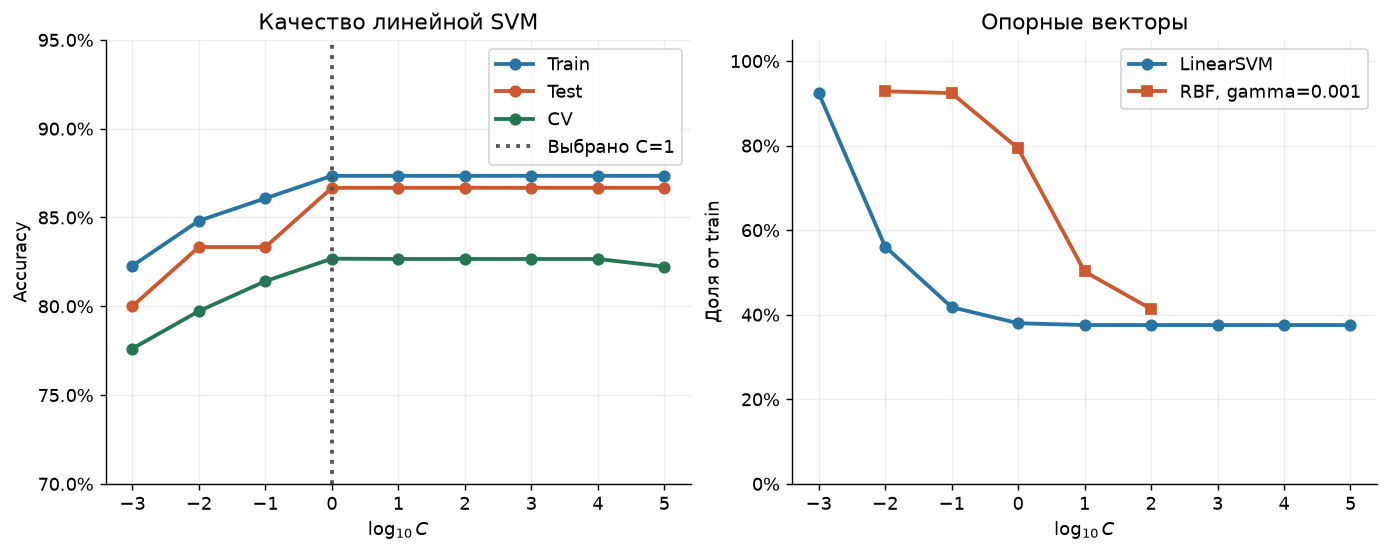

In [ ]:
plot_linear_heart()

### Пояснение к выбору C и опорным векторам

Для линейной модели я выбрал $C=1$: средняя CV accuracy составила 82.68%, train — 87.34%, test — 86.67%. При $C\ge10$ качество на тесте остаётся тем же, а CV не улучшается. Разница CV между $C=1$ и $C=10$ очень мала относительно разброса между фолдами, поэтому единственность лучшего параметра по этим данным утверждать нельзя.

На левом графике слишком малый штраф даёт более низкое качество. После увеличения $C$ кривые выходят на плато: дальнейшее усиление штрафа не устраняет перекрытие классов.

Справа доля опорных объектов LinearSVM падает с 219/237 = 92.4% при $C=0.001$ до 90/237 = 38.0% при $C=1$. При $C\ge10$ остаётся 89/237 = 37.6%. Для RBF с выбранным $\gamma=0.001$ доля также уменьшается при росте $C$; при $C=1$ она равна 188/237 = 79.3%.

У LinearSVM опорные объекты определены по активному ограничению $y_i f(x_i)+\xi_i=1$ с численным допуском, у DualSVM — по положительному $\alpha_i$ с допуском. Опорный объект может находиться на границе отступа, внутри коридора или быть ошибочно классифицированным. Поэтому 38% не означает, что у 38% пациентов медицински «пограничный диагноз». Эта доля характеризует построенную модель и её обучающую выборку.

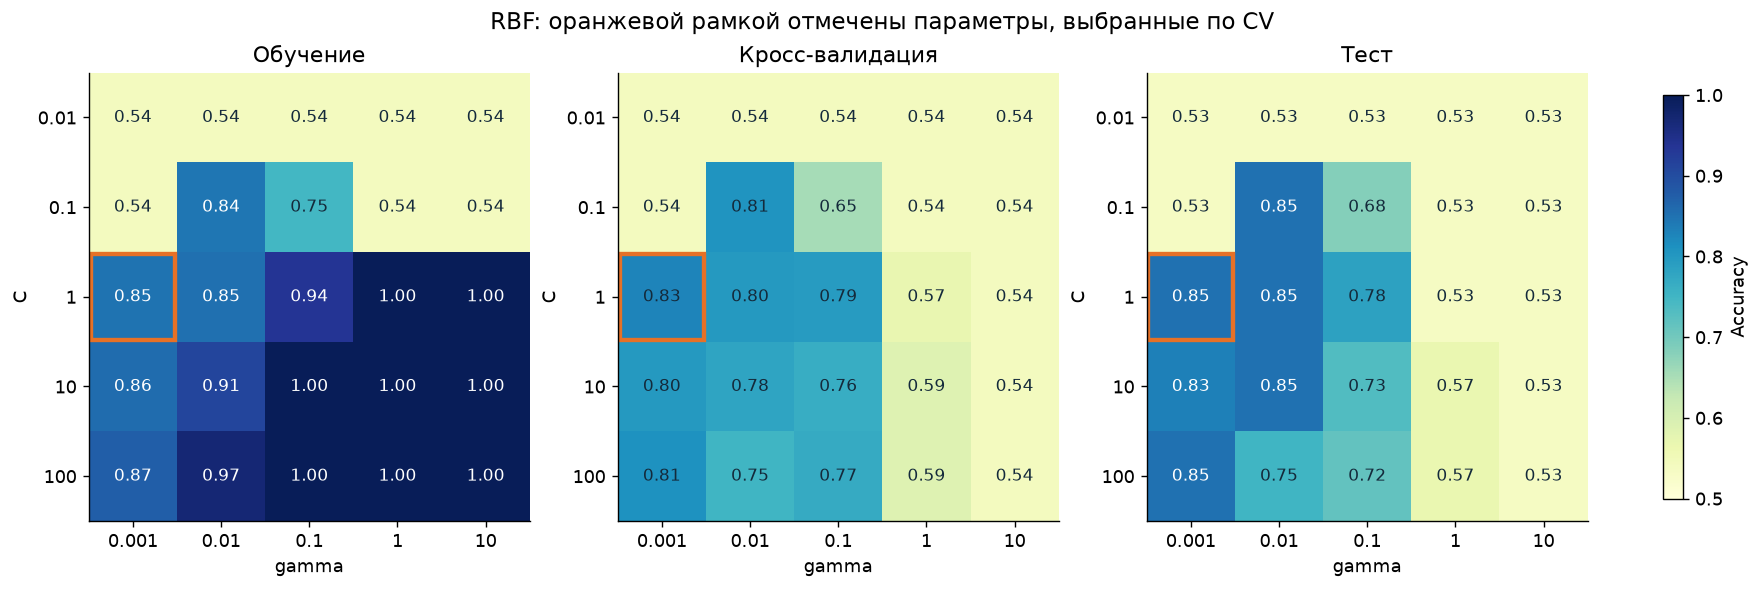

In [ ]:
plot_rbf_heart()

### Пояснение к RBF и выбор итоговой модели

Лучший результат RBF по CV получен при $C=1,\gamma=0.001$: CV — 82.68%, train — 84.81%, test — 85.00%. Его средняя CV accuracy совпала с результатом выбранной линейной модели. Оранжевая рамка на всех трёх картах отмечает это сочетание параметров.

При больших $\gamma$ модель способна очень точно воспроизводить обучающие метки, но качество на проверочных фолдах падает. Значит, сложная граница здесь не даёт устойчивого преимущества. Малые $C$ могут приводить к слишком сильной регуляризации и прогнозу преимущественно одного класса.

Я остановился на **LinearSVM с $C=1$**: при одинаковом среднем качестве CV она проще и позволяет интерпретировать веса. На тесте получено 52 верных ответа из 60 против 51 у RBF. Разница всего в один объект не доказывает, что линейный SVM всегда лучше для таких данных. Повторные разбиения могли бы дать другие оценки.

### 4.6. Проверка реализации и влияние масштабирования

Я обучил SVC с линейным и RBF-ядром на тех же масштабированных данных и с теми же параметрами, которые выбраны для собственных моделей. Затем повторил обучение своих моделей на исходном масштабе признаков. Во втором сравнении значения параметров зафиксированы, чтобы проверить именно влияние преобразования данных.

In [ ]:
#@title Проверка с SVC и эксперимент без масштабирования
reference_linear=SVC(C=best_C,kernel="linear",tol=1e-8).fit(X_train_scaled,y_train)
reference_rbf=SVC(C=best_rbf_C,kernel="rbf",gamma=best_gamma,tol=1e-8).fit(X_train_scaled,y_train)
checks=[]
for name,own,reference in [
    ("Линейное",linear_heart,reference_linear),("RBF",rbf_heart,reference_rbf)]:
    agreement=np.mean(own.predict(X_test_scaled)==reference.predict(X_test_scaled))
    checks.append({"Ядро":name,"Своя: train":own.score(X_train_scaled,y_train),
        "SVC: train":reference.score(X_train_scaled,y_train),
        "Своя: test":own.score(X_test_scaled,y_test),
        "SVC: test":reference.score(X_test_scaled,y_test),
        "Совпадение test":agreement})
    assert agreement==1.0
comparison=pd.DataFrame(checks)
display(comparison.round(4))
raw_linear=LinearSVM(C=best_C).fit(X_train.to_numpy(),y_train)
raw_rbf=DualSVM(C=best_rbf_C,kernel=partial(rbf_kernel,gamma=best_gamma)).fit(X_train.to_numpy(),y_train)
scale_records=[]
for name,scaled,raw in [("LinearSVM",linear_heart,raw_linear),("RBF",rbf_heart,raw_rbf)]:
    for label,model,A,B in [("С масштабированием",scaled,X_train_scaled,X_test_scaled),
                           ("Без масштабирования",raw,X_train.to_numpy(),X_test.to_numpy())]:
        scale_records.append({"Модель":name,"Подготовка":label,
            "Train":model.score(A,y_train),"Test":model.score(B,y_test)})
scale_results=pd.DataFrame(scale_records)
display(scale_results.round(4))
majority=int(y_train.value_counts().idxmax())
print("Test accuracy постоянного прогноза частого класса:",
      accuracy_score(y_test,np.full(len(y_test),majority)))
importance=pd.DataFrame({"Признак":X.columns,"Вес":linear_heart.weights_,
                         "|Вес|":np.abs(linear_heart.weights_)})
importance=importance.sort_values("|Вес|",ascending=False).reset_index(drop=True)
display(importance.round(4))
# Изменение линейной оценки при переходе dummy 0 -> 1.
# Оно отличается от веса для изменения на одно стандартное отклонение.
dummy_changes=pd.DataFrame({"Категория":[c for c in X.columns if "_" in c],
    "Изменение оценки 0→1":[linear_heart.weights_[j]/scaler.scale_[j]
                           for j,c in enumerate(X.columns) if "_" in c]})
assert all(m.solver_status_=="optimal" for m in heart_linear_models.values())
assert all(m.solver_status_=="optimal" for m in heart_rbf_models.values())
# Проверяем ограничения и разрыв целей у всех RBF-моделей полной train.
relative_gaps=[]
for model in heart_rbf_models.values():
    assert np.min(model.alpha_)>=-1e-6
    assert np.max(model.alpha_)<=model.C+1e-6
    assert abs(model.y_@model.alpha_)<1e-5
    gap=abs(model.primal_objective_-model.dual_objective_)/max(1,abs(model.primal_objective_))
    relative_gaps.append(gap)
assert max(relative_gaps)<1e-3
print("Проверки решений QP и сравнение с SVC пройдены.")

Test accuracy постоянного прогноза частого класса: 0.5333333333333333
Проверки решений QP и сравнение с SVC пройдены.


,Ядро,Своя: train,SVC: train,Своя: test,SVC: test,Совпадение test
0,Линейное,0.8734,0.8734,0.8667,0.8667,1.0
1,RBF,0.8481,0.8481,0.8500,0.8500,1.0


,Модель,Подготовка,Train,Test
0,LinearSVM,С масштабированием,0.8734,0.8667
1,LinearSVM,Без масштабирования,0.8734,0.8667
2,RBF,С масштабированием,0.8481,0.8500
3,RBF,Без масштабирования,0.7764,0.6833


,Признак,Вес,|Вес|
0,ca,0.7932,0.7932
1,oldpeak,0.4987,0.4987
2,sex,0.4258,0.4258
3,thal_7,0.3607,0.3607
4,cp_4,0.3365,0.3365
5,trestbps,0.3032,0.3032
6,cp_3,-0.2874,0.2874
7,slope_1,-0.2848,0.2848
8,cp_1,-0.2568,0.2568
9,thal_3,-0.2527,0.2527


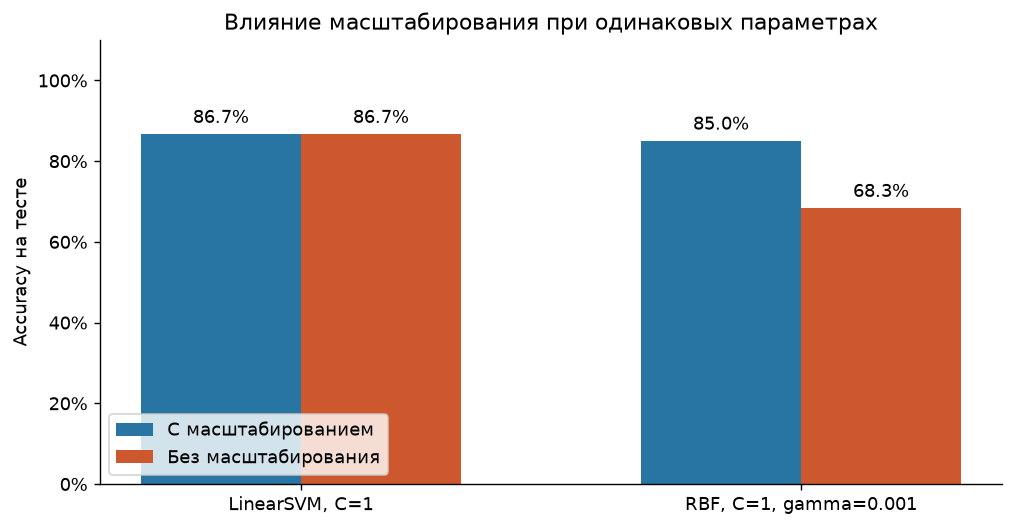

In [ ]:
plot_scaling_heart()



Для обоих ядер собственная реализация и SVC дали одинаковую accuracy на train и test. Все 60 тестовых прогнозов совпали. Проверки ограничений и близости прямой и двойственной целей у RBF-моделей также выполнены.

Без масштабирования у линейной модели при $C=1$ train accuracy осталась 87.34%, test accuracy — 86.67%. Значит, в этом конкретном разбиении ухудшение доли верных ответов не произошло. Однако стандартизация меняет соотношение штрафов на веса признаков в исходных единицах, поэтому одинаковая accuracy не означает, что масштабирование вообще не влияет на SVM.

Для RBF при $C=1,\gamma=0.001$ качество на тесте снизилось с 85.0% до 68.3%, на обучении — с 84.8% до 77.6%. Расстояния стали в большой степени определяться признаками с крупными численными значениями. При том же $\gamma$ многие пары объектов оказались почти несходными.

Это сравнение относится к **одинаковым гиперпараметрам**. Для данных без масштабирования оптимальное $\gamma$ могло бы быть другим. Постоянный прогноз наиболее частого класса даёт на тесте 53.3%, то есть обе выбранные масштабированные модели превосходят этот простой ориентир.

### 4.7. Какие признаки сильнее влияют на прогноз?

Я отсортировал признаки линейной модели по $|w_j|$. Поскольку признаки стандартизованы, вес показывает изменение линейной оценки при увеличении признака на одно обучающее стандартное отклонение. Положительный вес повышает оценку в сторону класса «есть заболевание», отрицательный понижает её.

Полная таблица весов приведена выше. На графике показаны 12 наибольших модулей. Для категорий важность относится к отдельному dummy-столбцу. Это не единая оценка важности всего исходного категориального признака.

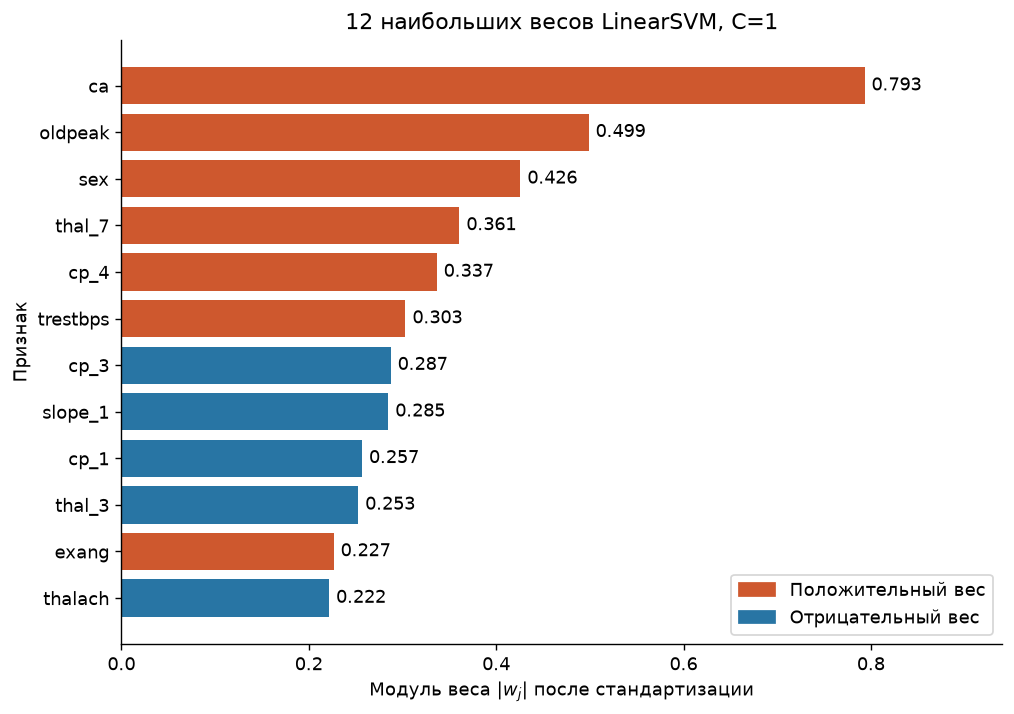

In [ ]:
plot_importance_heart()

### Пояснение к весам и медицинскому смыслу

Наибольшие модули весов получили ca (0.793), oldpeak (0.499), sex (0.426), thal_7 (0.361) и cp_4 (0.337). По [описанию UCI](https://archive.ics.uci.edu/dataset/45/heart+disease), ca — число крупных сосудов, видимых при флюороскопии, oldpeak — снижение сегмента ST при нагрузке относительно покоя, thal_7 — обратимый дефект, cp_4 — бессимптомная категория типа боли в груди. Эти признаки описывают результаты обследования и характер симптомов, поэтому их связь с прогнозом заболевания содержательно объяснима.

В этой модели отдельные категории боли в груди имеют больший модуль веса, чем холестерин (chol: 0.082) и возраст (age: 0.033). Результаты специализированных обследований оказались более информативными в данном линейном сочетании. Это не означает, что возраст или холестерин не имеют медицинского значения: модель оценивает их вклад совместно с остальными признаками, а корреляции могут перераспределять веса.

Знак и модуль коэффициента отражают условную связь в этой выборке, а не причинное влияние на болезнь. Для one-hot группы переход из категории A в B одновременно меняет два столбца; его эффект определяется разностью соответствующих коэффициентов с учётом масштаба. Поэтому отдельный положительный вес категории не следует понимать как самостоятельное медицинское правило.

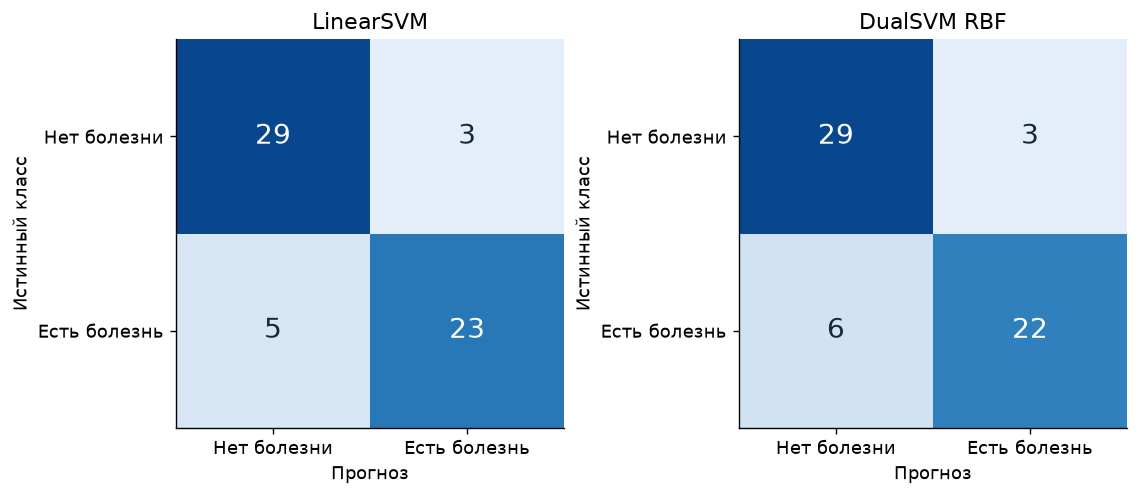

In [ ]:
plot_confusion_heart()

### Пояснение к ошибкам

На рисунке строки обозначают истинный класс, столбцы — прогноз. Линейная модель правильно классифицировала 29 из 32 объектов без заболевания и 23 из 28 объектов с заболеванием. Получены три ложноположительных и пять ложноотрицательных ответов. Полнота по классу заболевания равна 23/28 = 82.1%.

У RBF также три ложноположительных ответа, но шесть ложноотрицательных. Accuracy не показывает отдельно эти виды ошибок, поэтому матрицы ошибок дополняют сравнение. Исследование выполнено на небольшой учебной выборке и не устанавливает пригодность модели для медицинского применения.

## Вывод по заданию 4
Я подготовил реальные данные, подобрал параметры своих SVM и сравнил результаты с SVC. Линейная модель с C=1 и RBF с C=1, gamma=0.001 дали одинаковое среднее качество на кросс-валидации. Для итогового решения я выбрал более простую линейную модель, получившую 86.7% правильных ответов на тесте. Масштабирование заметно помогло RBF, а у линейной модели в этом разбиении доля верных ответов не изменилась. Среди наибольших весов оказались признаки обследований и отдельные категории симптомов. Выводы ограничены выбранной сеткой параметров и одним разбиением данных.

# Вывод

В ходе выполнения данной работы я изучил линейное и квадратичное программирование и решил задачи с ограничениями. Я реализовал линейный и двойственный SVM через QP-солвер. Эксперименты показали, что увеличение C не устраняет недостаток формы линейной границы на кольцах. Преобразование признаков и ядра позволили строить нелинейные границы, но избыточная гибкость приводила к переобучению. Для данных о болезнях сердца я обработал пропуски, закодировал категории и подобрал параметры по кросс-валидации. Итоговая линейная модель с C=1 дала 86.7% правильных ответов на тесте, а её прогнозы совпали с библиотечной реализацией. Полученные результаты показали важность подготовки данных и проверки качества на объектах, которые не использовались при обучении.